<div align="center">

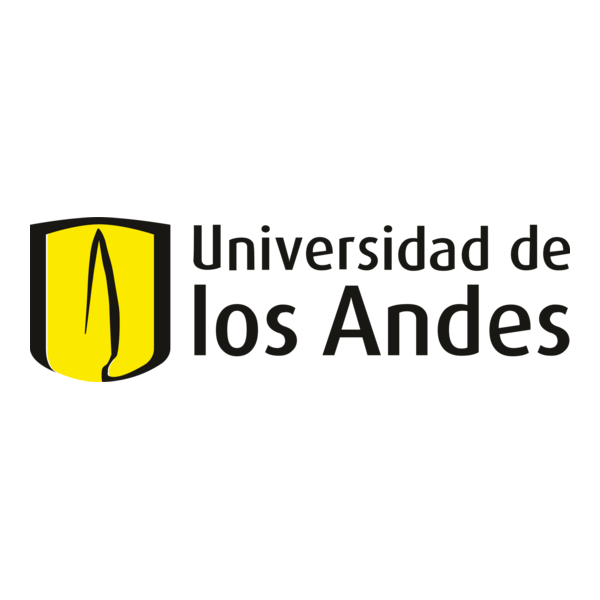

<h1>Proyecto de grado</h1>
<strong>Recuperación semántica y clasificación de la función de citas académicas en Computer Science</strong>
<p>Universidad de los Andes · Maestría en Inteligencia Artificial · Grupo 15</p>
<p>Sebastian Toro · Camilo Bejarano · German Rodriguez · Jose Arteaga</p>
</div>

En este notebook estudiamos si podemos reducir el sobreajuste del modelo base.
Recibe el contexto de la cita, el título y el resumen del artículo citado.
Comparamos el ajuste de referencia con más dropout y con mayor penalización de
los pesos. Cada entrenamiento empieza desde SciBERT preentrenado, no desde el
modelo final anterior. Este estudio es adicional y no reemplaza el test humano
ya publicado ni utiliza sus resultados para elegir ajustes.

**Alcance de los datos.** Usamos training v2 de G15 y aprovechamos las etiquetas
humanas de T_A que corresponden a filas permitidas de nuestra entrega, según el
[contrato, §§10 y 12](https://drive.google.com/file/d/1X7JXN5ZvoYJodhRxdT5Y-8wOaDlXwRXi/view)
y el [README de A3, §§3 y 4](https://drive.google.com/file/d/1m55jsSkHlb-MlCTJKgy36X4EIK8x23GN/view).
También se aplica a nuestra validación interna. Las reservas nunca anotadas conservan
su etiqueta automática. Nuestro conjunto humano T_B permanece separado del aprendizaje.

## 1. Nuestros datos y sus categorías

Empezamos viendo los ejemplos que realmente usamos: las clases, su distribución y
cuántas etiquetas son automáticas o revisadas por personas. Verificamos los archivos
y la separación por documento antes de dibujar las gráficas.


Mounted at /content/drive


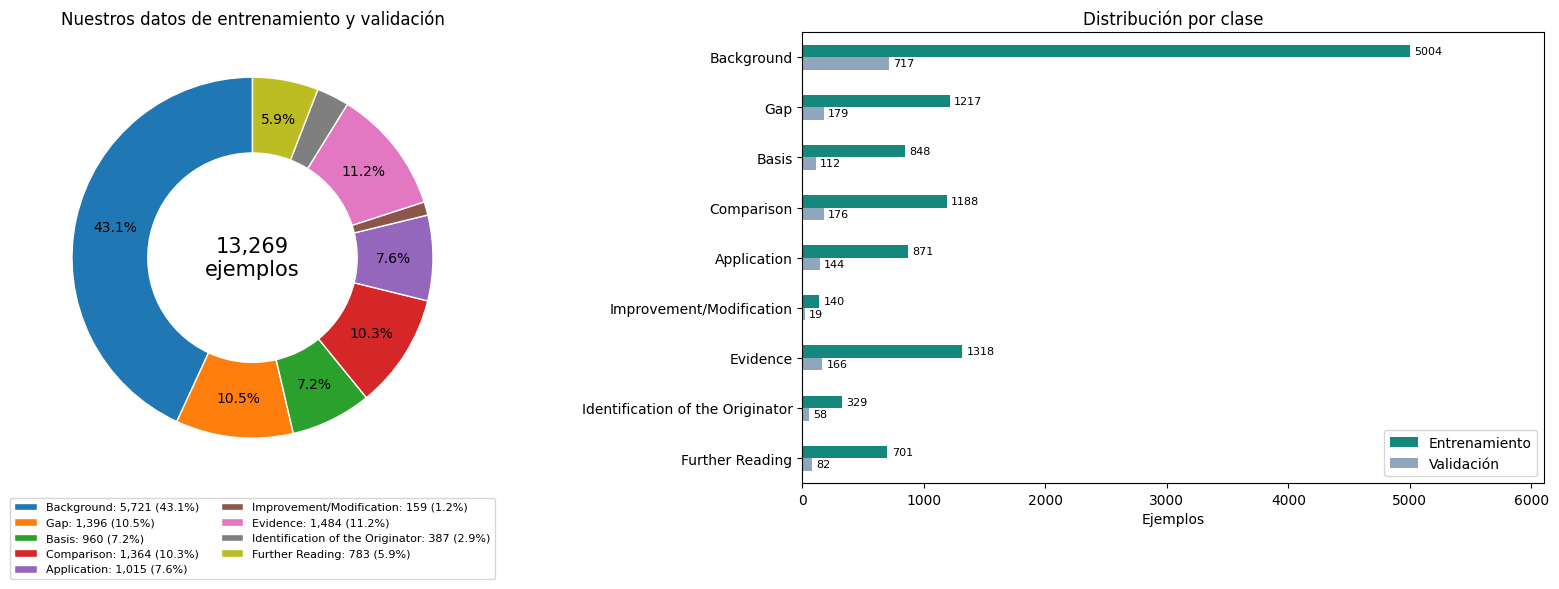

,Entrenamiento,Validación
Background,5004,717
Gap,1217,179
Basis,848,112
Comparison,1188,176
Application,871,144
Improvement/Modification,140,19
Evidence,1318,166
Identification of the Originator,329,58
Further Reading,701,82


,Entrenamiento,Validación
Etiqueta automática,10672,1528
Etiqueta humana,944,125


Usamos 11,616 ejemplos para entrenar y 1,653 para validar.
La clase más frecuente es Background (43.1%); la menos frecuente es Improvement/Modification (159 ejemplos).


In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import sys
import subprocess
import importlib.metadata
from pathlib import Path
import torch

# Comprobación técnica previa a cualquier preparación o entrenamiento.
if not torch.cuda.is_available() or "A100" not in torch.cuda.get_device_name(0) or not torch.cuda.is_bf16_supported():
    raise RuntimeError("La aceleración requerida no está disponible en el intérprete seleccionado.")
if torch.__version__.split("+")[0] != "2.11.0":
    raise RuntimeError("Se requiere PyTorch 2.11.0 para mantener la referencia técnica.")
PINNED = ["transformers==4.57.1","accelerate==1.11.0","datasets==4.3.0",
    "scikit-learn==1.7.2","matplotlib==3.10.7","safetensors==0.6.2","mlflow==3.17.2"]
installation = subprocess.run([sys.executable,"-m","pip","install","-q",*PINNED],capture_output=True,text=True)
if installation.returncode:
    raise RuntimeError("No se pudieron preparar las bibliotecas: " + installation.stdout[-1500:] + installation.stderr[-1500:])
for requirement in PINNED:
    package,expected = requirement.split("==")
    module = "sklearn" if package=="scikit-learn" else package
    loaded = sys.modules.get(module)
    if loaded is not None and getattr(loaded,"__version__",expected)!=expected:
        raise RuntimeError("Reinicia el intérprete para utilizar las versiones que acabamos de preparar.")

DATA_ROOT = Path(os.environ.get("SCIBERT_DATA_ROOT","/content/drive/MyDrive/MAIA_PROYECTO"))
RESULTS_ROOT = Path(os.environ.get("SCIBERT_RESULTS_ROOT","/content/drive/MyDrive/MAIA_TESIS"))
if not DATA_ROOT.is_dir() or not RESULTS_ROOT.is_dir():
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except ImportError as error:
        raise RuntimeError("Configura SCIBERT_DATA_ROOT y SCIBERT_RESULTS_ROOT con las carpetas accesibles.") from error
if not DATA_ROOT.is_dir() or not RESULTS_ROOT.is_dir():
    raise FileNotFoundError("Revisa las carpetas de entradas y resultados.")
if RESULTS_ROOT.resolve().is_relative_to(DATA_ROOT.resolve()):
    raise ValueError("La carpeta de resultados debe estar fuera de los datos compartidos.")

RUN_ID = "g15_scibert_base_regularizacion_01"
OUTPUT_ROOT = RESULTS_ROOT/"a4"/RUN_ID
TRACKING_ROOT = Path("/opt/maia/a4_tracking_experiments")/RUN_ID
SNAPSHOTS_ROOT = OUTPUT_ROOT/"_tracking/snapshots"
IDS_DIR = RESULTS_ROOT/"TrainingData_Grupo15_v2"
OLD_IDS_DIR = RESULTS_ROOT/"TrainingData_Grupo15"
A3_DIR = DATA_ROOT/"a3"
BATCH_DIR = DATA_ROOT/"a2/batches_norw"
TRAINING_MANIFEST_SHA256 = "c7dd23f92b2272338a9d98dec7cf86476937658aa09a8cd3706c9402be34e231"
A3_MANIFEST_SHA256 = "30118fea362fc4c0389ab34e2460d566d886d5dd7f11e8a84483b62b98a7ce5b"
MODEL_ID = "allenai/scibert_scivocab_uncased"
MODEL_REVISION = "24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1"
CONFIGS = ["base"]
SEED = 42
MAX_LENGTH = 512
CONTEXT_BUDGET = 192
TRAIN_BATCH = 16
GRAD_ACCUM = 2
EVAL_BATCH = 32
USE_BF16 = True
LABELS = ["Background","Gap","Basis","Comparison","Application","Improvement/Modification",
    "Evidence","Identification of the Originator","Further Reading"]
LABEL2ID = {label:i for i,label in enumerate(LABELS)}
ID2LABEL = dict(enumerate(LABELS))
import collections
import gc
import hashlib
import itertools
import json
import math
import shutil
import time
import uuid
import numpy as np
import pandas as pd
from IPython.display import display,Markdown

def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name + ".partial_" + uuid.uuid4().hex)
    temp.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False, default=str) + "\n", encoding="utf-8")
    os.replace(temp, path)

def freeze_json(path, value):
    path = Path(path)
    if path.exists() and json.loads(path.read_text(encoding="utf-8")) != value:
        raise ValueError(f"La configuración guardada es distinta: {path.name}. Usa otro RUN_ID.")
    save_json(path, value)

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def tree_hashes(directory):
    directory = Path(directory)
    return {p.relative_to(directory).as_posix(): sha256(p) for p in sorted(directory.rglob("*")) if p.is_file()}

def verify_files(directory, hashes):
    directory = Path(directory).resolve()
    if not hashes:
        raise ValueError("El cierre no contiene archivos verificables.")
    for name, expected in hashes.items():
        path = (directory / name).resolve()
        if not path.is_relative_to(directory) or not path.is_file() or sha256(path) != expected:
            raise ValueError(f"Archivo guardado ausente o modificado: {name}")

def prepare_final_data(ids_dir, a3_dir, old_ids_dir, output, labels, training_hash, a3_hash,
                       split_seed="G15-A4-split-v1", validation_fraction=.10):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    manifest, raw, gold, test_ids, hashes, closure = load_a3_release(
        ids_dir, a3_dir, old_ids_dir, labels, training_hash, a3_hash)
    rules = release_rules(read_records(Path(ids_dir) / "exclusion_list_G15_V2_v2.jsonl"))
    eligible = [dict(r) for r in raw if not release_excluded(r, rules)]
    labeled, unclear, corrected = attach_ta_gold(eligible, gold, labels)

    def validation_citing(citing):
        digest = hashlib.sha256(f"{split_seed}|val|{citing}".encode()).hexdigest()
        return int(digest[:16], 16) / 2**64 < validation_fraction

    validation = [r for r in labeled if validation_citing(r["citing_paper_id"])]
    candidates = [r for r in labeled if not validation_citing(r["citing_paper_id"])]
    val_docs = document_set(validation)
    train = [r for r in candidates if not {r["citing_paper_id"], r["cited_paper_id"]} & val_docs]
    audit_release_splits(train, validation, test_ids)
    splits = {"train": train, "validation": validation}
    counts = pd.DataFrame({k: collections.Counter(r["label"] for r in rows) for k, rows in splits.items()}).reindex(labels).fillna(0).astype(int)
    if counts.eq(0).any().any():
        raise ValueError("Cada clase debe estar representada en entrenamiento y validación.")
    if any(r.get("gold_set") == "B" or r.get("test_set") == "B" and r.get("sample_status") == "active"
           for rows in splits.values() for r in rows):
        raise ValueError("Una cita de la prueba propia intentó entrar al aprendizaje.")
    fields = ["inst_key", "group_key", "citing_paper_id", "cited_paper_id", "label", "label_source", "source_batch"]
    split_hashes = {}
    for name, rows in splits.items():
        rows.sort(key=lambda r: r["inst_key"])
        content = "".join(json.dumps({k: r[k] for k in fields}, ensure_ascii=False, sort_keys=True) + "\n" for r in rows)
        split_hashes[name] = hashlib.sha256(content.encode()).hexdigest()
        path = output / f"split_{name}_ids.jsonl"
        if path.exists() and path.read_text(encoding="utf-8") != content:
            raise ValueError("Las particiones cambiaron. Usa otro RUN_ID.")
        path.write_text(content, encoding="utf-8")
    source_counts = pd.DataFrame({k: collections.Counter(r["label_source"] for r in rows) for k, rows in splits.items()}).fillna(0).astype(int)
    counts.to_csv(output / "split_class_counts.csv")
    source_counts.to_csv(output / "split_label_sources.csv")
    summary = {"dataset_release": "training_v2", "isolation": "V2", "raw_rows": len(raw),
        "rows_after_exclusions": len(eligible), "removed_unclear": len(unclear),
        "corrected_prelabels": corrected, "removed_for_validation_isolation": len(candidates)-len(train),
        "rows": {k: len(v) for k, v in splits.items()}, "split_hashes": split_hashes,
        "input_hashes": hashes, "label_sources": source_counts.to_dict(),
        "split_seed": split_seed, "validation_fraction_target": validation_fraction,
        "temporal_split": False, "section_stratification": False, "test_scored": False,
        "contract_url": "https://drive.google.com/file/d/1X7JXN5ZvoYJodhRxdT5Y-8wOaDlXwRXi/view",
        "release_readme_url": "https://drive.google.com/file/d/1m55jsSkHlb-MlCTJKgy36X4EIK8x23GN/view"}
    freeze_json(output / "data_manifest.json", summary)
    save_json(output / "label_provenance.json", {"human_source_set": "A", "own_test_set": "B",
        "rule": "join by inst_key; replace eligible prelabels with final gold; never append own test",
        "source_counts": source_counts.to_dict(), "corrected_prelabels": corrected,
        "removed_unclear_keys": unclear})
    save_json(output / "a3_closure.json", closure)
    return splits, test_ids, hashes, split_hashes, counts, source_counts, summary

def show_final_data(counts, source_counts, output):
    import matplotlib.pyplot as plt
    totals = counts.sum(axis=1)
    fig, (pie, bars) = plt.subplots(1, 2, figsize=(17, 6))
    wedges, _, _ = pie.pie(totals, startangle=90, autopct=lambda p: f"{p:.1f}%" if p >= 3 else "",
        pctdistance=.78, colors=plt.get_cmap("tab10")(np.arange(len(totals))),
        wedgeprops={"width": .42, "edgecolor": "white"})
    pie.text(0, 0, f"{int(totals.sum()):,}\nejemplos", ha="center", va="center", fontsize=15)
    pie.set_title("Nuestros datos de entrenamiento y validación")
    pie.legend(wedges, [f"{k}: {v:,} ({v/totals.sum():.1%})" for k, v in totals.items()],
        loc="upper center", bbox_to_anchor=(.5, -.02), fontsize=8, ncol=2)
    counts.rename(columns={"train":"Entrenamiento", "validation":"Validación"}).plot.barh(ax=bars, color=["#16877c", "#8fa6be"])
    bars.invert_yaxis()
    for container in bars.containers:
        bars.bar_label(container, fmt="%.0f", padding=3, fontsize=8)
    bars.set(xlabel="Ejemplos", ylabel="", title="Distribución por clase")
    bars.set_xlim(0, int(counts.train.max())*1.22)
    fig.tight_layout()
    fig.savefig(Path(output)/"eda_class_distribution.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    display(counts.rename(columns={"train":"Entrenamiento", "validation":"Validación"}))
    display(source_counts.rename(index={"pre_label":"Etiqueta automática", "human_gold":"Etiqueta humana"},
        columns={"train":"Entrenamiento", "validation":"Validación"}))
    print(f"Usamos {int(counts.train.sum()):,} ejemplos para entrenar y {int(counts.validation.sum()):,} para validar.")
    print(f"La clase más frecuente es {totals.idxmax()} ({totals.max()/totals.sum():.1%}); la menos frecuente es {totals.idxmin()} ({int(totals.min()):,} ejemplos).")

def file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def read_records(path):
    with Path(path).open(encoding="utf-8-sig") as stream:
        return [json.loads(line) for line in stream if line.strip()]

def keyed_records(rows, name):
    result = {}
    for row in rows:
        key = row["inst_key"]
        if key in result:
            raise ValueError(f"Hay una clave repetida en {name}: {key}")
        citing, para, span, cited = key.split("|")
        if citing != row["citing_paper_id"] or cited != row["cited_paper_id"] or citing == cited:
            raise ValueError(f"La clave no corresponde a sus artículos en {name}: {key}")
        if not row["group_key"].startswith(f"{citing}|{para}|"):
            raise ValueError(f"El grupo de citas no corresponde a la clave en {name}: {key}")
        result[key] = row
    return result

def checked_file(root, name, expected, hashes):
    root = Path(root).resolve()
    path = (root / name).resolve()
    if path.parent != root:
        raise ValueError("El manifiesto contiene una ruta fuera de su carpeta.")
    actual = file_hash(path)
    if actual != expected:
        raise ValueError(f"El archivo cambió respecto de la entrega revisada: {name}")
    hashes[str(path)] = actual
    return path

def load_a3_release(ids_dir, a3_dir, old_ids_dir, labels, training_manifest_hash, metrics_manifest_hash):
    ids_dir, a3_dir, old_ids_dir = map(Path, [ids_dir, a3_dir, old_ids_dir])
    hashes = {}
    manifest_path = checked_file(ids_dir, "manifest_training_v2_G15.json", training_manifest_hash, hashes)
    metrics_path = checked_file(a3_dir, "manifest_metrics.json", metrics_manifest_hash, hashes)
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
    if (manifest["group"], manifest["test_set"], manifest["version"], manifest["variant"]) != ("G15", "B", "v2", "V0"):
        raise ValueError("Esta corrida espera la entrega training v2 de G15, cuyo punto de partida es V0.")
    required = {"training_v2_G15.jsonl", *(f"exclusion_list_G15_{v}_v2.jsonl" for v in ["V0", "V1", "V2"])}
    if not required <= manifest["files"].keys():
        raise ValueError("Faltan archivos de entrenamiento o de exclusión en el manifiesto.")
    for name, digest in manifest["files"].items():
        checked_file(ids_dir, name, digest, hashes)
    gold_path = checked_file(a3_dir, "test_set_gold.jsonl", metrics["files"]["test_set_gold.jsonl"], hashes)
    rows, gold = read_records(ids_dir / "training_v2_G15.jsonl"), read_records(gold_path)
    row_index, gold_index = keyed_records(rows, "training v2"), keyed_records(gold, "gold A3")
    if len(rows) != manifest["v2_rows"] or len(gold) != metrics["packages"]:
        raise ValueError("La cantidad de filas no coincide con los manifiestos.")
    if not all(r["high_confidence"] and r["primary_pre_label"] in labels for r in rows):
        raise ValueError("Hay una fila sin preetiqueta válida de alta confianza.")
    for record in gold:
        if record["set"] not in {"A", "B"} or type(record["in_eval"]) is not bool:
            raise ValueError("Conjunto o marca in_eval inválidos en A3.")
        if record["gold_primary"] not in labels + ["unclear"]:
            raise ValueError("Hay una categoría humana desconocida.")
        if record["in_eval"] != (record["gold_primary"] != "unclear"):
            raise ValueError("La etiqueta humana y su marca de evaluación se contradicen.")
    for group in ["A", "B"]:
        valid = sum(r["set"] == group and r["in_eval"] for r in gold)
        unclear = sum(r["set"] == group and not r["in_eval"] for r in gold)
        if valid != metrics["in_eval"][group] or unclear != metrics["unclear"][group]:
            raise ValueError("El cierre humano no coincide con su manifiesto.")
    own_gold = [g for g in gold if g["set"] == "B"]
    if set(row_index) & {g["inst_key"] for g in own_gold}:
        raise ValueError("Se encontró una cita de T_B dentro del entrenamiento: detener.")
    # Recuperar localizadores, no etiquetas antiguas, para identificar el test de A3.
    old_manifest_path = old_ids_dir / "manifest_training_v1_G15.json"
    old_manifest = json.loads(old_manifest_path.read_text(encoding="utf-8"))
    hashes[str(old_manifest_path)] = file_hash(old_manifest_path)
    for name in ["training_v1_G15.jsonl", "test_set_ids_G15.jsonl"]:
        checked_file(old_ids_dir, name, old_manifest["files"][name], hashes)
    old_rows = read_records(old_ids_dir / "training_v1_G15.jsonl")
    old_index = keyed_records(old_rows, "training v1")
    old_test_index = keyed_records(read_records(old_ids_dir / "test_set_ids_G15.jsonl"), "test IDs v1")
    if not old_index.keys() <= row_index.keys() or len(old_rows) != manifest["v1_rows"]:
        raise ValueError("La entrega v2 no conserva todas las filas de v1.")
    regained = [r for r in rows if r["inst_key"] not in old_index]
    if len(regained) != manifest["rows_regained"] or dict(collections.Counter(r["primary_pre_label"] for r in regained)) != manifest["regained_per_label"]:
        raise ValueError("Las reservas recuperadas no coinciden con el manifiesto.")
    test_ids = []
    for record in own_gold:
        if record["inst_key"] not in old_test_index:
            raise ValueError("Una cita del cierre T_B no está en sus identificadores originales.")
        source = old_test_index[record["inst_key"]]
        test_ids.append({k: source[k] for k in ["inst_key", "group_key", "citing_paper_id", "cited_paper_id", "source_batch"]})
    closure_counts = collections.Counter(r["gold_primary"] for r in own_gold if r["in_eval"])
    expected = {"Background": 330, "Gap": 310, "Basis": 322, "Comparison": 313,
                "Application": 400, "Improvement/Modification": 268, "Evidence": 386,
                "Identification of the Originator": 324, "Further Reading": 315}
    if dict(closure_counts) != expected:
        raise ValueError("Los cupos de T_B difieren del cierre revisado del 9 de noviembre.")
    closure = {"date": "2026-11-09", "valid_test_rows": metrics["in_eval"]["B"],
               "unclear_test_rows": metrics["unclear"]["B"], "valid_test_counts": dict(closure_counts),
               "quota_note": "Cierre sin ola 4: Improvement/Modification tiene 268 casos válidos, según iaa_report.",
               "test_scored": False, "dataset_release": "training_v2", "regained_rows": len(regained)}
    return manifest, rows, gold, test_ids, hashes, closure

def release_rules(rows):
    rules = {"citing": set(), "cited": set()}
    for row in rows:
        if row["group"] != "G15" or row["role"] not in rules:
            raise ValueError("La lista de exclusión no corresponde a G15 o tiene un rol desconocido.")
        rules[row["role"]].add(row["paper_id"])
    return rules

def release_excluded(row, rules):
    return row["citing_paper_id"] in rules["citing"] or row["cited_paper_id"] in rules["cited"]

def attach_ta_gold(rows, gold, labels):
    index = keyed_records(gold, "gold A3")
    labeled, dropped, corrected = [], [], 0
    for row in rows:
        human = index.get(row["inst_key"])
        if human is not None and human["set"] != "A":
            raise ValueError("Solo se permite incorporar etiquetas humanas de T_A al entrenamiento.")
        if human is not None and not human["in_eval"]:
            dropped.append(row["inst_key"])
            continue
        label = human["gold_primary"] if human else row["primary_pre_label"]
        if label not in labels:
            raise ValueError("Hay una etiqueta de entrenamiento desconocida.")
        corrected += bool(human and label != row["primary_pre_label"])
        labeled.append({**row, "label": label, "label_source": "human_gold" if human else "pre_label",
                        "gold_set": "A" if human else None})
    return labeled, dropped, corrected

def document_set(rows):
    return {r[key] for r in rows for key in ["citing_paper_id", "cited_paper_id"]}

def audit_release_splits(train, validation, test_ids):
    pairs = [("train", train), ("validation", validation), ("test_reserved", test_ids)]
    for i, (name, rows) in enumerate(pairs):
        for other_name, other in pairs[i + 1:]:
            if document_set(rows) & document_set(other):
                raise ValueError(f"Hay documentos compartidos entre {name} y {other_name}.")

splits,test_ids,input_hashes,split_hashes,counts,source_counts,data_manifest = prepare_final_data(
    IDS_DIR,A3_DIR,OLD_IDS_DIR,OUTPUT_ROOT,LABELS,TRAINING_MANIFEST_SHA256,A3_MANIFEST_SHA256)
train_rows,val_rows = splits["train"],splits["validation"]
show_final_data(counts,source_counts,OUTPUT_ROOT)
ENVIRONMENT = {"python":sys.version,"torch":torch.__version__,"cuda":torch.version.cuda,
    "gpu":torch.cuda.get_device_name(0),"bf16":USE_BF16,
    "packages":{p.split("==")[0]:importlib.metadata.version(p.split("==")[0]) for p in PINNED}}
save_json(OUTPUT_ROOT/"environment.json",ENVIRONMENT)

EXPECTED_SPLITS = {"train":"7636b0a0a2704c9e04a22cbb6ad9140b9fc65dc5bb8f5761f6a8b141d2fe5a02", "validation":"f7b544a3f787f5a40f101f57ac4662ad49e27a9296dfdd19e5d67b50afc7223f"}
if split_hashes != EXPECTED_SPLITS:
    raise ValueError("Las particiones difieren de las del estudio de referencia.")


## 2. Reunimos los textos de cada cita

Unimos los identificadores con su contexto, título, resumen y tres fragmentos.
Comprobamos que las dos entradas tengan información completa y que cada contexto
señale una sola cita objetivo. La comparación conservará las mismas citas en todos los ensayos.


In [2]:
def read_jsonl(path):
    with Path(path).open(encoding="utf-8-sig") as f:
        for n, line in enumerate(f, 1):
            if line.strip():
                try:
                    row = json.loads(line)
                except json.JSONDecodeError as e:
                    raise ValueError(f"JSON inválido: {path}:{n}") from e
                if not isinstance(row, dict):
                    raise ValueError(f"Se esperaba un objeto: {path}:{n}")
                yield row

BATCH_FIELDS = {
    "inst_key": "inst_key", "context": "context",
    "title": "cited_title", "abstract": "cited_abstract", "chunks": "top3",
}
CHUNK_FIELDS = {"text": "text", "section": "section"}

def field_at(row, dotted):
    value = row
    for part in dotted.split("."):
        if not isinstance(value, dict) or part not in value:
            raise KeyError(f"Campo '{dotted}' ausente. Ajusta el adaptador con el esquema real.")
        value = value[part]
    return value

required_batches = sorted({r["source_batch"] for rows in splits.values() for r in rows})
batch_paths = {name: BATCH_DIR / f"{name}.jsonl" for name in required_batches}
missing = [str(p) for p in batch_paths.values() if not p.is_file()]
if missing:
    raise FileNotFoundError("Faltan lotes con texto; descárgalos de a2/batches_norw/:\n" + "\n".join(missing))
freeze_json(OUTPUT_ROOT / "batch_manifest.json", {
    "hashes": {name: sha256(path) for name, path in batch_paths.items()},
    "batch_fields": BATCH_FIELDS, "chunk_fields": CHUNK_FIELDS,
})


def require_text(value, name):
    if not isinstance(value, str) or not value.strip():
        raise ValueError(f"Texto vacío o tipo incorrecto: {name}")
    return value.strip()

def normalize_batch(row):
    out = {k: require_text(field_at(row, BATCH_FIELDS[k]), k)
           for k in ("inst_key", "context", "title", "abstract")}
    if out["context"].count("[[TARGET]]") != 1:
        raise ValueError(f"Se requiere un [[TARGET]] por contexto: {out['inst_key']}")
    if "{{cite:" in out["context"]:
        raise ValueError("Quedan marcadores crudos. Usa el renderizador congelado de A2.")
    raw_chunks = field_at(row, BATCH_FIELDS["chunks"])
    if not isinstance(raw_chunks, list) or len(raw_chunks) != 3:
        raise ValueError(f"Top-3 incompleto: {out['inst_key']}")
    out["chunks"] = []
    for ch in raw_chunks:
        text = require_text(field_at(ch, CHUNK_FIELDS["text"]), "chunk.text")
        section = field_at(ch, CHUNK_FIELDS["section"])
        if section is not None and not isinstance(section, str):
            raise ValueError(f"Tipo incorrecto de sección: {out['inst_key']}")
        missing_section = section is None or not section.strip()
        out["chunks"].append({"text": text, "section": "Unknown" if missing_section else section.strip(),
                              "section_missing": missing_section})
    return out

needed = {r["inst_key"]: r["source_batch"] for rows in splits.values() for r in rows}
texts = {}
for batch, path in batch_paths.items():
    input_hashes[str(path)] = sha256(path)
    seen_batch = set()
    for raw in read_jsonl(path):
        key = field_at(raw, BATCH_FIELDS["inst_key"])
        if key in seen_batch:
            raise ValueError(f"Clave duplicada en {batch}: {key}")
        seen_batch.add(key)
        if key in needed and needed[key] == batch:
            texts[key] = normalize_batch(raw)
missing_keys = sorted(needed.keys() - texts.keys())
if missing_keys:
    raise ValueError(f"Sin reconstruir: {len(missing_keys)}. Primeras claves: {missing_keys[:5]}")
assert len(texts) == len(needed)
save_json(OUTPUT_ROOT / "reconstruction_audit.json", {
    "required_rows": len(needed), "reconstructed_rows": len(texts),
    "batches": required_batches, "adapter": BATCH_FIELDS, "chunk_adapter": CHUNK_FIELDS,
    "rows_with_missing_section": sum(any(ch["section_missing"] for ch in ex["chunks"]) for ex in texts.values()),
    "chunks_with_missing_section": sum(ch["section_missing"] for ex in texts.values() for ch in ex["chunks"]),
})
section_rows = []
for split, rows in splits.items():
    cnt = collections.Counter(ch["section"] for r in rows for ch in texts[r["inst_key"]]["chunks"])
    section_rows.extend({"split": split, "section": sec, "chunks": n} for sec, n in cnt.items())
pd.DataFrame(section_rows).to_csv(OUTPUT_ROOT / "section_distribution.csv", index=False)
print(f"Reconstruidas {len(texts):,} instancias con ambas configuraciones completas.")


Reconstruidas 13,269 instancias con ambas configuraciones completas.


## 3. Preparamos la entrada del modelo base

Conservamos el mismo texto y la misma distribución del espacio: hasta 192 tokens
para el contexto, hasta 64 para el título y el resto para el resumen, con 512 en
total incluidos los separadores. El modelo recibe texto, que convertimos a IDs;
no recibe fragmentos Top-3 en este experimento.


In [3]:
import inspect
from datasets import Dataset
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION, use_fast=True,token=False)
MARKERS = ["[[TARGET]]", "[CITE]", "[FORMULA]", "[FIGURE]", "[TABLE]"]
tokenizer.add_special_tokens({"additional_special_tokens": MARKERS})
TARGET_ID = tokenizer.convert_tokens_to_ids("[[TARGET]]")

def fair_caps(lengths, budget):
    caps = [0] * len(lengths)
    remaining = budget
    while remaining and any(c < n for c, n in zip(caps, lengths)):
        for i, n in enumerate(lengths):
            if remaining and caps[i] < n:
                caps[i] += 1
                remaining -= 1
    return caps

def encode_example(example, config, tok, max_length=512, context_budget=192):
    ids = lambda s: tok.encode(s, add_special_tokens=False)
    context = ids(example["context"])
    target_id = tok.convert_tokens_to_ids("[[TARGET]]")
    if context.count(target_id) != 1:
        raise ValueError("El contexto debe contener exactamente un marcador objetivo.")
    target = context.index(target_id)
    start = max(0, min(target - context_budget // 2, len(context) - context_budget))
    context_cut = context[start:start + context_budget]
    assert tok.num_special_tokens_to_add(pair=True) == 3, "Se requiere tokenizador BERT."
    budget = max_length - 3 - len(context_cut)
    assert budget >= 32 and target_id in context_cut
    stats = {"context_original": len(context), "context_kept": len(context_cut)}
    if config == "base":
        title = ids("Title: " + example["title"])
        abstract = ids("Abstract: " + example["abstract"])
        title_kept = title[:min(64, budget // 3)]
        abstract_kept = abstract[:budget - len(title_kept)]
        evidence = title_kept + abstract_kept
        stats.update(evidence_original=len(title) + len(abstract), evidence_kept=len(evidence),
                     title_original=len(title), title_kept=len(title_kept),
                     abstract_original=len(abstract), abstract_kept=len(abstract_kept))
    elif config == "fragmentos":
        sections = [ids(f"Section: {ch['section']} Passage: ")[:24] for ch in example["chunks"]]
        bodies = [ids(ch["text"]) for ch in example["chunks"]]
        caps = fair_caps([len(h) + len(b) for h, b in zip(sections, bodies)], budget)
        evidence = []
        for i, (head, body, cap) in enumerate(zip(sections, bodies, caps), 1):
            kept = (head + body)[:cap]
            if len(kept) <= len(head):
                raise ValueError("Presupuesto insuficiente para conservar texto de cada chunk.")
            evidence.extend(kept)
            stats[f"chunk{i}_original"] = len(head) + len(body)
            stats[f"chunk{i}_kept"] = len(kept)
        stats.update(evidence_original=sum(len(h) + len(b) for h, b in zip(sections, bodies)),
                     evidence_kept=len(evidence))
    else:
        raise ValueError(config)
    input_ids = [tok.cls_token_id] + context_cut + [tok.sep_token_id] + evidence + [tok.sep_token_id]
    token_types = [0] * (len(context_cut) + 2) + [1] * (len(evidence) + 1)
    assert len(input_ids) <= max_length and len(token_types) == len(input_ids)
    stats["total_tokens"] = len(input_ids)
    return {"input_ids": input_ids, "attention_mask": [1] * len(input_ids),
            "token_type_ids": token_types}, stats

encoded = {}
audit_rows = []
for config in CONFIGS:
    encoded[config] = {}
    for split, rows in splits.items():
        features = []
        for row in rows:
            features_row, stats = encode_example(texts[row["inst_key"]], config, tokenizer,
                                                  MAX_LENGTH, CONTEXT_BUDGET)
            features.append({**features_row, "labels": LABEL2ID[row["label"]]})
            audit_rows.append({"config": config, "split": split, "inst_key": row["inst_key"], **stats})
        encoded[config][split] = Dataset.from_list(features)
audit = pd.DataFrame(audit_rows)
audit["context_truncated"] = audit.context_kept < audit.context_original
audit["evidence_truncated"] = audit.evidence_kept < audit.evidence_original
audit.to_csv(OUTPUT_ROOT / "token_budget_audit.csv", index=False)
display(audit.groupby(["config", "split"])[["total_tokens", "context_truncated", "evidence_truncated"]].mean())

ENCODER_SOURCE = inspect.getsource(fair_caps) + "\n" + inspect.getsource(encode_example)


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

total_tokens  context_truncated  evidence_truncated
config split                                                          
base   train         389.606319           0.373020            0.069904
       validation    389.548094           0.356322            0.071385

## 4. Fijamos las tres condiciones antes de entrenar

El control usa dropout 0,10 y weight decay 0,10. Cambiamos una decisión por vez:
dropout 0,20 o weight decay 0,20. El dropout se aplica a las capas ocultas,
atención y cabeza clasificadora. Conservamos ritmo 3e-5 y batch efectivo 32.

Entrenamos las tres condiciones con semillas 42, 17 y 73: nueve ensayos.
Cada uno llega como máximo a seis épocas y se detiene tras dos evaluaciones
sin mejorar la pérdida de validación. Recuperamos el checkpoint de menor pérdida
del entrenamiento BF16 y lo verificamos en FP32. Todas las condiciones usan ese
nuevo criterio, incluido el control, para no confundirlo con el efecto del dropout.

Comparamos la pérdida FP32 media entre semillas, el F1 y las curvas. La condición
con menor pérdida media identifica una candidata exploratoria; conservamos la
semilla 42. Una pérdida menor no garantiza un F1 mayor ni elimina el sobreajuste.
No evaluamos el test ni afirmamos una mejora sobre él.


In [4]:
MAX_EPOCHS = 6
PATIENCE = 2
REPETITION_SEEDS = [42,17,73]
CONDITIONS = [{"condition":"control","dropout":.1,"weight_decay":.1},
              {"condition":"dropout_020","dropout":.2,"weight_decay":.1},
              {"condition":"weight_decay_020","dropout":.1,"weight_decay":.2}]

def trial_id(spec):
    return f"regularizacion_base_{spec['condition']}_s{spec['seed']}"

PLAN = [{"stage":"regularizacion","input_variant":"base",**condition,
         "learning_rate":3e-5,"seed":seed,"max_epochs":MAX_EPOCHS}
        for condition in CONDITIONS for seed in REPETITION_SEEDS]
assert len({trial_id(t) for t in PLAN})==9
STUDY_SPEC = {"schema_version":1,"study_id":RUN_ID,"model_id":MODEL_ID,
    "model_revision":MODEL_REVISION,"split_hashes":split_hashes,"input_hashes":input_hashes,
    "label_mapping":LABEL2ID,"plan":PLAN,"primary_seed":42,"test_scored":False,
    "max_epochs":MAX_EPOCHS,"patience":PATIENCE,"checkpoint_metric":"eval_loss",
    "checkpoint_greater_is_better":False,"condition_selection":"mean_validation_fp32_cross_entropy",
    "control_policy":"same new loss stopping rule for all conditions",
    "token_policy":{"max_length":MAX_LENGTH,"context_budget":CONTEXT_BUDGET,
        "encoder_sha256":hashlib.sha256(ENCODER_SOURCE.encode()).hexdigest()},
    "train_batch":TRAIN_BATCH,"gradient_accumulation":GRAD_ACCUM,"eval_batch":EVAL_BATCH,
    "precision":"bf16_training_fp32_reporting","environment":ENVIRONMENT}
freeze_json(OUTPUT_ROOT/"study_manifest.json",STUDY_SPEC)
pd.DataFrame(PLAN).to_csv(OUTPUT_ROOT/"trial_plan.csv",index=False)
display(pd.DataFrame(PLAN))


,stage,input_variant,condition,dropout,weight_decay,learning_rate,seed,max_epochs
0,regularizacion,base,control,0.1,0.1,0.00003,42,6
1,regularizacion,base,control,0.1,0.1,0.00003,17,6
2,regularizacion,base,control,0.1,0.1,0.00003,73,6
3,regularizacion,base,dropout_020,0.2,0.1,0.00003,42,6
4,regularizacion,base,dropout_020,0.2,0.1,0.00003,17,6
5,regularizacion,base,dropout_020,0.2,0.1,0.00003,73,6
6,regularizacion,base,weight_decay_020,0.1,0.2,0.00003,42,6
7,regularizacion,base,weight_decay_020,0.1,0.2,0.00003,17,6
8,regularizacion,base,weight_decay_020,0.1,0.2,0.00003,73,6


## 5. Guardamos la historia del experimento

MLflow registra cada combinación, sus curvas y sus métricas. Los modelos y puntos
de recuperación se guardan con identificadores distintos. Si se interrumpe una
ejecución, verificamos lo guardado y recuperamos los ensayos completos o su último
punto de entrenamiento. Conservamos el historial acumulado en respaldos de Drive.


In [5]:
from types import SimpleNamespace
import importlib.util
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,precision_recall_fscore_support,f1_score
from transformers import AutoModelForSequenceClassification,DataCollatorWithPadding,Trainer,TrainingArguments,EarlyStoppingCallback,set_seed
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
def compute_metrics(prediction):
    logits = prediction.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    pred = np.asarray(logits).argmax(axis=-1)
    y = prediction.label_ids
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=list(ID2LABEL),
                                               average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y, pred), "precision_macro": p,
            "recall_macro": r, "f1_macro": f,
            "f1_micro": f1_score(y, pred, labels=list(ID2LABEL), average="micro", zero_division=0)}
INFERENCE_TEMPLATE = 'import json\nfrom pathlib import Path\nimport torch\nfrom transformers import AutoTokenizer, AutoModelForSequenceClassification\n\n__ENCODER__\n\nclass CitationClassifier:\n    def __init__(self, model_dir, device=None):\n        self.root = Path(model_dir)\n        self.policy = json.loads((self.root / "input_policy.json").read_text(encoding="utf-8"))\n        self.tokenizer = AutoTokenizer.from_pretrained(self.root, local_files_only=True)\n        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")\n        self.model = AutoModelForSequenceClassification.from_pretrained(self.root, local_files_only=True, attn_implementation="eager").to(self.device).eval()\n\n    def predict(self, example):\n        features, stats = encode_example(example, self.policy["config"], self.tokenizer,\n                                         self.policy["max_length"], self.policy["context_budget"])\n        batch = {k: torch.tensor([v], device=self.device) for k, v in features.items()}\n        with torch.inference_mode():\n            probs = self.model(**batch).logits.float().softmax(-1)[0].cpu().tolist()\n        best = max(range(len(probs)), key=probs.__getitem__)\n        return {"label": self.model.config.id2label[best], "score": probs[best],\n                "scores": {self.model.config.id2label[i]: p for i, p in enumerate(probs)},\n                "score_calibrated": False, "token_audit": stats}\n'
"""Evaluación del modelo exportado; se incrusta en la sección 12 del notebook."""
from pathlib import Path
from types import SimpleNamespace
import gc
import numpy as np
import torch
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding, Trainer, TrainingArguments


def probability_metrics(labels, probabilities):
    labels = np.asarray(labels)
    probabilities = np.asarray(probabilities)
    predictions = probabilities.argmax(axis=-1)
    classes = list(range(probabilities.shape[1]))
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, labels=classes, average="macro", zero_division=0)
    return {"accuracy": float(accuracy_score(labels, predictions)),
            "precision_macro": float(precision), "recall_macro": float(recall),
            "f1_macro": float(f1), "f1_micro": float(f1_score(
                labels, predictions, labels=classes, average="micro", zero_division=0))}


def compare_probabilities(reference, actual, keys, atol=2e-5, rtol=1e-4):
    reference, actual = np.asarray(reference), np.asarray(actual)
    if reference.shape != actual.shape or reference.ndim != 2 or len(keys) != len(actual) or not len(actual):
        raise ValueError("Las predicciones no tienen las mismas filas y clases")
    for values in [reference, actual]:
        if not np.isfinite(values).all() or (values < 0).any() or (values > 1).any():
            raise ValueError("Probabilidades inválidas")
        if not np.allclose(values.sum(axis=1), 1, atol=1e-5):
            raise ValueError("Las probabilidades no suman uno")
    changed = reference.argmax(-1) != actual.argmax(-1)
    return {"n": len(keys), "atol": atol, "rtol": rtol,
            "probabilities_close": bool(np.allclose(reference, actual, atol=atol, rtol=rtol)),
            "max_absolute_difference": float(np.abs(reference - actual).max()),
            "label_disagreements": int(changed.sum()),
            "changed_inst_keys": [key for key, differs in zip(keys, changed) if differs]}


def predict_export_fp32(classifier, data, batch_size):
    classifier.model.float().eval()
    collator = DataCollatorWithPadding(classifier.tokenizer, pad_to_multiple_of=8)
    probabilities = []
    for start in range(0, len(data), batch_size):
        items = [{k: v for k, v in data[i].items() if k != "labels"}
                 for i in range(start, min(start + batch_size, len(data)))]
        batch = {k: v.to(classifier.device) for k, v in collator(items).items()}
        # Explícito incluso si el llamador usa un contexto autocast externo.
        with torch.inference_mode(), torch.autocast(device_type=torch.device(classifier.device).type, enabled=False):
            probabilities.extend(classifier.model(**batch).logits.float().softmax(-1).cpu().tolist())
    return np.asarray(probabilities)


def audit_export(classifier, data, keys, checkpoint, output_dir, batch_size, seed, mixed_precision):
    """Compara checkpoint/exportación en FP32 y reproduce la ruta de Trainer.

    Nunca entrena ni modifica el checkpoint o la exportación existente.
    Si falta el checkpoint, la auditoría de exportación queda explícitamente pendiente.
    """
    if mixed_precision not in {"bf16", "fp16", "fp32"}:
        raise ValueError("Precisión de Trainer no reconocida")
    if classifier.model.config._attn_implementation != "eager":
        raise ValueError("La comparación requiere atención eager en ambas rutas")
    probabilities = predict_export_fp32(classifier, data, batch_size)
    has_checkpoint = bool(checkpoint and Path(checkpoint).is_dir())
    source = Path(checkpoint) if has_checkpoint else classifier.root
    reference_model = AutoModelForSequenceClassification.from_pretrained(
        source, local_files_only=True, attn_implementation="eager").float().to(classifier.device).eval()
    try:
        audit = {"evaluation_policy": "v2_fp32", "canonical_precision": "fp32", "attention_implementation": "eager",
                 "trainer_precision": mixed_precision, "reference_source": str(source),
                 "export_check": "pending_checkpoint_missing"}
        if has_checkpoint:
            reference = SimpleNamespace(model=reference_model, tokenizer=classifier.tokenizer, device=classifier.device)
            expected = predict_export_fp32(reference, data, batch_size)
            comparison = compare_probabilities(expected, probabilities, keys)
            audit["checkpoint_vs_export_fp32"] = comparison
            if not comparison["probabilities_close"] or comparison["label_disagreements"]:
                raise ValueError(f"La exportación no reproduce el checkpoint: {comparison}")
            audit["export_check"] = "passed_full_validation"
        args = TrainingArguments(output_dir=str(Path(output_dir) / "trainer_prediction"),
            per_device_eval_batch_size=batch_size, report_to="none", seed=seed,
            use_cpu=torch.device(classifier.device).type == "cpu",
            bf16=mixed_precision == "bf16", fp16=mixed_precision == "fp16", tf32=False,
            dataloader_num_workers=0, disable_tqdm=False)
        trainer = Trainer(model=reference_model, args=args, processing_class=classifier.tokenizer,
            data_collator=DataCollatorWithPadding(classifier.tokenizer, pad_to_multiple_of=8))
        prediction = trainer.predict(data)
        logits = prediction.predictions[0] if isinstance(prediction.predictions, tuple) else prediction.predictions
        trainer_probabilities = torch.as_tensor(logits).float().softmax(-1).numpy()
        audit["trainer_vs_export_fp32"] = compare_probabilities(trainer_probabilities, probabilities, keys)
        return probabilities, trainer_probabilities, audit
    finally:
        del reference_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

"""Se incrusta en el notebook: no requiere subir este archivo a Colab."""
import contextlib
import datetime as dt
import math
import numbers
import sqlite3
import tempfile
import uuid
import zipfile
from pathlib import PurePosixPath
import mlflow
from mlflow import MlflowClient
from transformers import TrainerCallback


def tracking_restore(root, snapshots):
    """Solo restaura antes de abrir MLflow; nunca sobrescribe una DB local."""
    root.mkdir(parents=True, exist_ok=True)
    if (root / "mlflow.db").exists():
        return
    candidates = sorted((p.parent for p in snapshots.glob("*/COMPLETE.json")),
        key=lambda p: dt.datetime.fromisoformat(json.loads((p / "COMPLETE.json").read_text())["created_at_utc"]))
    if not candidates:
        print("Sin historial previo: se creará una base MLflow nueva.")
        return
    source = candidates[-1]
    receipt = json.loads((source / "COMPLETE.json").read_text())
    archive_path = source / "snapshot.zip"
    assert receipt["schema_version"] == 1
    assert receipt["snapshot_id"] == source.name
    assert receipt["mlflow_version"] == mlflow.__version__
    assert archive_path.stat().st_size == receipt["zip_size"]
    assert sha256(archive_path) == receipt["zip_sha256"]
    assert (source / "snapshot.sha256").read_text().split()[0] == receipt["zip_sha256"]
    # Validar todo antes de copiar a las rutas canónicas.
    with tempfile.TemporaryDirectory() as tmp:
        target = Path(tmp)
        with zipfile.ZipFile(archive_path) as archive:
            names = archive.namelist()
            assert len(names) == len(set(names))
            manifest = json.loads(archive.read("snapshot_manifest.json"))
            assert manifest["schema_version"] == 1
            assert manifest["snapshot_id"] == receipt["snapshot_id"]
            assert manifest["canonical_root"] == str(root)
            assert manifest["mlflow_version"] == mlflow.__version__
            assert set(names) == set(manifest["files"]) | {"snapshot_manifest.json"}
            for entry in archive.infolist():
                path = PurePosixPath(entry.filename)
                assert not path.is_absolute() and ".." not in path.parts
                assert "\\" not in entry.filename and ":" not in entry.filename
                assert (entry.external_attr >> 16) & 0o170000 != 0o120000
                assert entry.filename in {"mlflow.db", "snapshot_manifest.json"} or entry.filename.startswith("artifacts/")
            archive.extractall(target)
        for name, metadata in manifest["files"].items():
            path = target / name
            assert path.stat().st_size == metadata["size"] and sha256(path) == metadata["sha256"]
        with contextlib.closing(sqlite3.connect(target / "mlflow.db")) as db:
            assert db.execute("PRAGMA integrity_check").fetchone()[0] == "ok"
        assert not (root / "artifacts").exists(), "Hay artefactos locales sin DB; usa una sesión limpia."
        if (target / "artifacts").exists():
            shutil.copytree(target / "artifacts", root / "artifacts")
        shutil.copyfile(target / "mlflow.db", root / "mlflow.db")
    print("Historial restaurado:", source.name)


class A4Tracking:
    def __init__(self, root, snapshots, output, run_id, interval=300):
        self.root, self.snapshots, self.output = Path(root), Path(snapshots), Path(output)
        self.run_id, self.interval = run_id, interval
        self.last_backup = 0
        self.parents, self.attempts = {}, {}
        self.snapshots.mkdir(parents=True, exist_ok=True)
        tracking_restore(self.root, self.snapshots)
        mlflow.set_tracking_uri("sqlite:///" + (self.root / "mlflow.db").as_posix())
        self.client = MlflowClient()
        name = "G15_SciBERT_Base_Regularizacion"
        experiment = self.client.get_experiment_by_name(name)
        self.experiment = (experiment.experiment_id if experiment else
            self.client.create_experiment(name, artifact_location=(self.root / "artifacts/scibert_final").as_uri()))
        # Solo el mismo RUN_ID: las sesiones anteriores terminaron sin cierre.
        previous = self.client.search_runs([self.experiment], filter_string=f"tags.a4_run_id = '{run_id}'")
        for run in previous:
            if run.info.status == "RUNNING":
                self.client.set_terminated(run.info.run_id, status="KILLED")
        self.backup(force=True)

    def backup(self, force=False):
        if not force and time.monotonic() - self.last_backup < self.interval:
            return
        created = dt.datetime.now(dt.timezone.utc)
        sid = created.strftime("%Y%m%dT%H%M%S%fZ_") + uuid.uuid4().hex[:8]
        with tempfile.TemporaryDirectory() as tmp:
            stage = Path(tmp) / "stage"
            stage.mkdir()
            with contextlib.closing(sqlite3.connect(self.root / "mlflow.db")) as source:
                with contextlib.closing(sqlite3.connect(stage / "mlflow.db")) as dest:
                    source.backup(dest)
                    assert dest.execute("PRAGMA integrity_check").fetchone()[0] == "ok"
            if (self.root / "artifacts").exists():
                shutil.copytree(self.root / "artifacts", stage / "artifacts")
            paths = sorted(p for p in stage.rglob("*") if p.is_file())
            assert not any(p.is_symlink() for p in stage.rglob("*"))
            manifest = dict(schema_version=1, snapshot_id=sid, created_at_utc=created.isoformat(),
                mlflow_version=mlflow.__version__, canonical_root=str(self.root), purpose="scibert_training",
                files={p.relative_to(stage).as_posix(): {"sha256": sha256(p), "size": p.stat().st_size} for p in paths})
            save_json(stage / "snapshot_manifest.json", manifest)
            packed = Path(tmp) / "snapshot.zip"
            with zipfile.ZipFile(packed, "w", zipfile.ZIP_DEFLATED) as archive:
                for path in sorted(p for p in stage.rglob("*") if p.is_file()):
                    archive.write(path, path.relative_to(stage).as_posix())
            digest = sha256(packed)
            destination = self.snapshots / sid
            destination.mkdir(exist_ok=False)
            shutil.copyfile(packed, destination / "snapshot.zip")
            assert sha256(destination / "snapshot.zip") == digest
            (destination / "snapshot.sha256").write_text(f"{digest}  snapshot.zip\n")
            save_json(destination / "COMPLETE.json", dict(schema_version=1, snapshot_id=sid,
                created_at_utc=created.isoformat(), mlflow_version=mlflow.__version__,
                zip_sha256=digest, zip_size=packed.stat().st_size))
        self.last_backup = time.monotonic()
        print("MLflow respaldado:", destination)

    def parent(self, config):
        if config not in self.parents:
            runs = self.client.search_runs([self.experiment],
                filter_string=f"tags.a4_run_id = '{self.run_id}' and tags.config = '{config}' and tags.kind = 'configuration'")
            if len(runs) > 1:
                raise ValueError("Más de un padre para la misma configuración")
            self.parents[config] = (runs[0].info.run_id if runs else self.client.create_run(self.experiment,
                tags={"mlflow.runName": f"{self.run_id}/{config}", "a4_run_id": self.run_id,
                      "config": config, "kind": "configuration"}).info.run_id)
        return self.parents[config]

    def metrics(self, run, values, step=0):
        for key, value in values.items():
            if isinstance(value, numbers.Real) and math.isfinite(float(value)):
                self.client.log_metric(run, key, float(value), step=int(step))

    def reports(self, config, run=None):
        run = run or self.parent(config)
        for directory, artifact_path in [(self.output, "provenance"), (self.output / "trials" / config, "reports")]:
            for path in sorted(directory.iterdir()):
                if path.is_file() and path.suffix in {".json", ".csv", ".png", ".txt"}:
                    self.client.log_artifact(run, str(path), artifact_path=artifact_path)

    @contextlib.contextmanager
    def evaluation(self, config, directory, policy="v2_fp32"):
        parent = self.parent(config)
        rid = self.client.create_run(self.experiment, tags={
            "mlflow.runName": f"{config}/evaluation_{policy}_{uuid.uuid4().hex[:8]}",
            "mlflow.parentRunId": parent, "a4_run_id": self.run_id, "config": config,
            "kind": "evaluation", "evaluation_policy": policy,
            "canonical_precision": "fp32", "drive_output": str(directory)}).info.run_id
        try:
            yield rid
            self.client.log_artifacts(rid, str(directory), artifact_path="evaluation")
            self.client.set_terminated(rid, "FINISHED")
            self.client.set_tag(parent, "latest_evaluation_run", rid)
            self.backup(force=True)
        except BaseException as error:
            self.client.set_tag(rid, "failure", f"{type(error).__name__}: {error}"[:2000])
            self.client.set_terminated(rid, "KILLED" if isinstance(error, KeyboardInterrupt) else "FAILED")
            try:
                self.backup(force=True)
            except Exception as backup_error:
                print("Falló el respaldo de evaluación:", backup_error)
            raise

    @contextlib.contextmanager
    def attempt(self, config, spec, checkpoint):
        parent = self.parent(config)
        self.client.update_run(parent, status="RUNNING")
        rid = self.client.create_run(self.experiment, tags={"mlflow.runName": f"{config}/attempt_{uuid.uuid4().hex[:8]}",
            "mlflow.parentRunId": parent, "a4_run_id": self.run_id, "config": config,
            "kind": "attempt", "validation_reference": "prelabels_and_available_gold"}).info.run_id
        self.attempts[config] = rid
        try:
            (self.output / "trials" / config).mkdir(parents=True, exist_ok=True)
            for key, value in spec.items():
                if not isinstance(value, (dict, list)):
                    self.client.log_param(rid, key, str(value)[:5000])
            self.client.log_param(rid, "config", config)
            self.client.log_param(rid, "resume_checkpoint", str(checkpoint))
            self.client.set_tag(rid, "drive_output", str(self.output / "trials" / config))
            self.reports(config, rid)
            self.backup(force=True)
            yield rid
        except BaseException as error:
            self.client.set_tag(rid, "failure", f"{type(error).__name__}: {error}"[:2000])
            self.client.set_terminated(rid, "KILLED" if isinstance(error, KeyboardInterrupt) else "FAILED")
            self.client.set_terminated(parent, "FAILED")
            try:
                self.backup(force=True)
            except Exception as backup_error:
                print("Falló el respaldo de cierre:", backup_error)
            raise
        else:
            self.reports(config, rid)
            self.client.set_terminated(rid, "FINISHED")
            self.client.set_terminated(parent, "FINISHED")
            self.backup(force=True)


def commit_checkpoint(path):
    path = Path(path)
    required = ["trainer_state.json", "optimizer.pt", "scheduler.pt", "training_args.bin"]
    assert all((path / name).is_file() for name in required)
    assert list(path.glob("*safetensors")) or list(path.glob("pytorch_model*.bin"))
    assert list(path.glob("rng_state*.pth")), "Falta el estado aleatorio para reanudar"
    files = {p.name: {"sha256": sha256(p), "size": p.stat().st_size} for p in path.iterdir() if p.is_file() and p.name != "A4_COMPLETE.json"}
    save_json(path / "A4_COMPLETE.json", {"files": files})


def verified_checkpoint(directory):
    directory = Path(directory)
    candidates = sorted(directory.glob("checkpoint-*"), key=lambda p: int(p.name.split("-")[-1]), reverse=True)
    for path in candidates:
        if not (path / "A4_COMPLETE.json").exists():
            print("Se omite checkpoint sin cierre:", path)
            continue
        files = json.loads((path / "A4_COMPLETE.json").read_text())["files"]
        if all((path / name).is_file() and (path / name).stat().st_size == meta["size"] and sha256(path / name) == meta["sha256"] for name, meta in files.items()):
            # Trainer vuelve a cargar también el mejor checkpoint previo.
            state = json.loads((path / "trainer_state.json").read_text())
            best = state.get("best_model_checkpoint")
            if best and not Path(best).is_dir():
                raise ValueError(f"Falta el mejor checkpoint requerido: {best}")
            if best and Path(best) != path:
                marker = Path(best) / "A4_COMPLETE.json"
                assert marker.is_file(), "El mejor checkpoint previo no tiene cierre"
                best_files = json.loads(marker.read_text())["files"]
                assert all((Path(best) / name).is_file() and sha256(Path(best) / name) == meta["sha256"]
                           for name, meta in best_files.items()), "Mejor checkpoint previo corrupto"
            return str(path)
        print("Se omite checkpoint con hashes inválidos:", path)
    if candidates:
        raise ValueError("Hay checkpoints pero ninguno completo. No se reinicia silenciosamente.")
    return None


class A4MLflowCallback(TrainerCallback):
    def __init__(self, tracking, run):
        self.tracking, self.run = tracking, run

    def on_log(self, args, state, control, logs=None, **kwargs):
        self.tracking.metrics(self.run, logs or {}, state.global_step)

    def on_step_end(self, args, state, control, **kwargs):
        self.tracking.backup()

    def on_save(self, args, state, control, **kwargs):
        path = Path(args.output_dir) / f"checkpoint-{state.global_step}"
        commit_checkpoint(path)
        self.tracking.client.set_tag(self.run, "latest_complete_checkpoint", str(path))
        self.tracking.client.log_artifact(self.run, str(path / "A4_COMPLETE.json"),
            artifact_path=f"checkpoints/{path.name}")
        self.tracking.backup(force=True)

def trial_id(spec):
    return f"regularizacion_base_{spec['condition']}_s{spec['seed']}"


def grid_plan(configs, learning_rates, weight_decays, seed, max_epochs):
    result = [{"stage":"grid", "input_variant":c, "learning_rate":float(lr), "weight_decay":float(wd),
        "seed":int(seed), "max_epochs":int(max_epochs)} for c, lr, wd in itertools.product(configs, learning_rates, weight_decays)]
    ids = [trial_id(s) for s in result]
    if not result or len(set(ids)) != len(ids):
        raise ValueError("La búsqueda contiene combinaciones vacías o repetidas.")
    if any(s["learning_rate"] <= 0 or s["weight_decay"] < 0 or s["max_epochs"] < 1 for s in result):
        raise ValueError("Los parámetros de la búsqueda no son válidos.")
    return result

def select_winners(results, plan):
    expected = {trial_id(s) for s in plan}
    if len(results) != len(expected) or {r["trial_id"] for r in results} != expected:
        raise ValueError("La selección requiere todos los ensayos de la búsqueda, sin duplicados.")
    if any(r["stage"] != "grid" or r["evaluation_policy"] != "v2_fp32" or not math.isfinite(r["f1_macro"]) for r in results):
        raise ValueError("La selección requiere resultados FP32 válidos de la búsqueda.")
    specs = {trial_id(s): s for s in plan}
    for r in results:
        s = specs[r["trial_id"]]
        if any(r[k] != s[k] for k in s):
            raise ValueError("El resultado no corresponde a la combinación declarada.")
    # Desempate fijado antes de entrenar: menor LR, menor regularización e ID.
    return {c: min((r for r in results if r["input_variant"] == c),
            key=lambda r:(-r["f1_macro"],r["learning_rate"],r["weight_decay"],r["trial_id"]))
            for c in sorted({s["input_variant"] for s in plan})}

def repetition_plan(winners, seeds, primary_seed=42):
    seeds = list(map(int, seeds))
    if len(seeds) != len(set(seeds)) or primary_seed not in seeds:
        raise ValueError("Las semillas deben ser únicas e incluir la semilla principal.")
    return [{"stage":"repeticion", "input_variant":c, "learning_rate":r["learning_rate"],
        "weight_decay":r["weight_decay"], "seed":s, "max_epochs":r["max_epochs"]}
        for c,r in sorted(winners.items()) for s in seeds if s != primary_seed]

def stability_table(winners, repeated, seeds, primary_seed=42):
    all_rows = [*winners.values(), *repeated]
    for config in winners:
        rows = [r for r in all_rows if r["input_variant"] == config]
        if len(rows) != len(seeds) or {r["seed"] for r in rows} != set(seeds):
            raise ValueError("Faltan repeticiones o hay una semilla duplicada.")
        w = winners[config]
        if w["seed"] != primary_seed or any(r["evaluation_policy"] != "v2_fp32" or
            any(r[k] != w[k] for k in ["learning_rate","weight_decay","max_epochs"]) for r in rows):
            raise ValueError("Las repeticiones deben conservar los ajustes seleccionados.")
    frame = pd.DataFrame(all_rows)
    return frame.groupby("input_variant").agg(n=("f1_macro","size"),mean_f1=("f1_macro","mean"),
        std_f1=("f1_macro","std"),min_f1=("f1_macro","min"),max_f1=("f1_macro","max"))

def completed_trial(workdir, spec):
    workdir = Path(workdir)
    stored = workdir / "trial_spec.json"
    if stored.exists() and json.loads(stored.read_text()) != spec:
        raise ValueError("Los ajustes de un ensayo existente cambiaron.")
    train_marker = workdir / "TRAINING_COMPLETE.json"
    if train_marker.exists():
        verify_files(workdir/"model", json.loads(train_marker.read_text())["model_hashes"])
    marker = workdir / "EVALUATION_COMPLETE.json"
    if not marker.exists():
        return None
    if not train_marker.exists():
        raise ValueError("Hay una evaluación sin un modelo verificado.")
    verify_files(workdir/"evaluation", json.loads(marker.read_text())["files"])
    result = json.loads((workdir/"evaluation/result.json").read_text())
    if (result["trial_id"] != workdir.name or result["model_marker_sha256"] != sha256(train_marker)
            or any(result.get(k) != v for k,v in spec["trial"].items())):
        raise ValueError("El cierre de evaluación no corresponde al ensayo.")
    return result

def load_trial_export(model_dir):
    module_spec = importlib.util.spec_from_file_location("scibert_inference_"+uuid.uuid4().hex, Path(model_dir)/"inference.py")
    module = importlib.util.module_from_spec(module_spec)
    previous = sys.dont_write_bytecode
    try:
        sys.dont_write_bytecode = True
        module_spec.loader.exec_module(module)
    finally:
        sys.dont_write_bytecode = previous
    return module.CitationClassifier(model_dir)

def run_final_trial(trial):
    name = trial_id(trial)
    workdir = OUTPUT_ROOT/"trials"/name
    workdir.mkdir(parents=True,exist_ok=True)
    spec = {"study":STUDY_SPEC,"trial":trial}
    freeze_json(workdir/"trial_spec.json",spec)
    previous = completed_trial(workdir,spec)
    if previous is not None:
        parent = tracking.parent(name)
        tracking.client.set_tag(parent,"input_variant",trial["input_variant"])
        tracking.client.set_tag(parent,"stage",trial["stage"])
        tracking.client.set_tag(parent,"export_check","passed_full_validation")
        tracking.metrics(parent,{f"validation_fp32_{k}":v for k,v in previous.items()})
        tracking.client.log_artifacts(parent,str(workdir/"evaluation"),artifact_path="validation")
        tracking.reports(name)
        tracking.client.set_terminated(parent,"FINISHED")
        print(name, "comprobado; resultado recuperado.")
        return previous
    checkpoint_dir = workdir/"checkpoints"
    trained = workdir/"TRAINING_COMPLETE.json"
    last = verified_checkpoint(checkpoint_dir) if not trained.exists() and checkpoint_dir.exists() else None
    params = {"study_id":RUN_ID,"input_variant":trial["input_variant"],"stage":trial["stage"],
        "learning_rate":trial["learning_rate"],"weight_decay":trial["weight_decay"],
        "seed":trial["seed"],"max_epochs":trial["max_epochs"],"early_stopping_patience":PATIENCE,
        "train_batch":TRAIN_BATCH,"gradient_accumulation":GRAD_ACCUM,"max_length":MAX_LENGTH,
        "dropout":trial["dropout"],"condition":trial["condition"],"checkpoint_metric":"eval_loss",
        "evaluation_policy":"v2_fp32","isolation":"V2","dataset_release":"training_v2","test_scored":False}
    with tracking.attempt(name,params,last) as attempt_id:
        parent = tracking.parent(name)
        for k in ["input_variant","stage"]:
            tracking.client.set_tag(parent,k,trial[k])
        tracking.client.set_tag(parent,"trial_drive",str(workdir))
        if not trained.exists():
            set_seed(trial["seed"])
            model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID,revision=MODEL_REVISION,
                token=False,num_labels=len(LABELS),id2label=ID2LABEL,label2id=LABEL2ID,
                problem_type="single_label_classification",attn_implementation="eager",
                hidden_dropout_prob=trial["dropout"],attention_probs_dropout_prob=trial["dropout"],
                classifier_dropout=trial["dropout"])
            model.resize_token_embeddings(len(tokenizer),mean_resizing=False)
            args = TrainingArguments(output_dir=str(checkpoint_dir),num_train_epochs=trial["max_epochs"],
                learning_rate=trial["learning_rate"],weight_decay=trial["weight_decay"],
                per_device_train_batch_size=TRAIN_BATCH,gradient_accumulation_steps=GRAD_ACCUM,
                per_device_eval_batch_size=EVAL_BATCH,warmup_ratio=.1,lr_scheduler_type="linear",
                eval_strategy="epoch",save_strategy="epoch",logging_strategy="steps",logging_steps=50,
                load_best_model_at_end=True,metric_for_best_model="loss",greater_is_better=False,
                save_total_limit=2,save_safetensors=True,seed=trial["seed"],data_seed=trial["seed"],
                restore_callback_states_from_checkpoint=True,bf16=USE_BF16,fp16=False,tf32=False,
                full_determinism=True,dataloader_num_workers=0,dataloader_pin_memory=True,
                optim="adamw_torch",report_to="none",push_to_hub=False)
            trainer = Trainer(model=model,args=args,train_dataset=encoded[trial["input_variant"]]["train"],
                eval_dataset=encoded[trial["input_variant"]]["validation"],processing_class=tokenizer,
                data_collator=DataCollatorWithPadding(tokenizer,pad_to_multiple_of=8),compute_metrics=compute_metrics,
                callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE),A4MLflowCallback(tracking,attempt_id)])
            torch.cuda.reset_peak_memory_stats()
            started = time.perf_counter()
            trained_result = trainer.train(resume_from_checkpoint=last)
            torch.cuda.synchronize()
            elapsed = time.perf_counter()-started
            checkpoint = trainer.state.best_model_checkpoint
            best_epoch = json.loads((Path(checkpoint)/"trainer_state.json").read_text())["epoch"]
            model_dir = workdir/"model"
            trainer.save_model(str(model_dir))
            tokenizer.save_pretrained(model_dir)
            save_json(model_dir/"input_policy.json",{"config":trial["input_variant"],"max_length":MAX_LENGTH,
                "context_budget":CONTEXT_BUDGET,"markers":MARKERS,"model_revision":MODEL_REVISION,"score_calibrated":False})
            save_json(model_dir/"label_mapping.json",{"label2id":LABEL2ID,"id2label":ID2LABEL})
            save_json(model_dir/"run_manifest.json",spec)
            (model_dir/"inference.py").write_text(INFERENCE_TEMPLATE.replace("__ENCODER__",ENCODER_SOURCE),encoding="utf-8")
            save_json(model_dir/"api_contract.json",{"input_variant":trial["input_variant"],
                "required_input":["context","title","abstract"] if trial["input_variant"]=="base" else ["context","chunks: 3 objetos {text, section}"],
                "context_target":"Un marcador [[TARGET]]", "output":"Una clase y nueve probabilidades sin calibrar"})
            metadata = {"best_checkpoint":checkpoint,"best_epoch":best_epoch,
                "epochs_completed":trainer.state.epoch,"best_trainer_eval_loss":trainer.state.best_metric,
                "elapsed_session_seconds":elapsed,"peak_gpu_allocated_gib":torch.cuda.max_memory_allocated()/2**30,
                "train_metrics":trained_result.metrics}
            save_json(workdir/"training_metrics.json",metadata)
            save_json(workdir/"training_log.json",trainer.state.log_history)
            save_json(trained,{"model_hashes":tree_hashes(model_dir),"attempt_id":attempt_id})
            del trainer,model
            gc.collect()
            torch.cuda.empty_cache()
        result = evaluate_final_trial(trial,workdir,attempt_id)
        tracking.client.log_artifacts(attempt_id,str(workdir/"evaluation"),artifact_path="validation")
        tracking.client.log_artifact(attempt_id,str(workdir/"training_log.json"),artifact_path="training")
        tracking.client.log_artifact(attempt_id,str(workdir/"training_metrics.json"),artifact_path="training")
        tracking.client.log_artifact(attempt_id,str(workdir/"trial_spec.json"),artifact_path="provenance")
        tracking.client.set_tag(parent,"model_drive",str(workdir/"model"))
        return result

def evaluate_final_trial(trial, workdir, attempt_id):
    import matplotlib.pyplot as plt
    workdir = Path(workdir)
    directory = workdir/"evaluation"
    directory.mkdir(exist_ok=True)
    train_info = json.loads((workdir/"training_metrics.json").read_text())
    clf = load_trial_export(workdir/"model")
    try:
        data = encoded[trial["input_variant"]]["validation"]
        sample = clf.predict(texts[val_rows[0]["inst_key"]])
        one = predict_export_fp32(clf,data.select([0]),EVAL_BATCH)[0]
        if not np.allclose(one,[sample["scores"][k] for k in LABELS],atol=2e-5):
            raise ValueError("La preparación de entradas exportada difiere del entrenamiento.")
        probs,replay,audit = audit_export(clf,data,[r["inst_key"] for r in val_rows],train_info["best_checkpoint"],
            directory,EVAL_BATCH,trial["seed"],"bf16" if USE_BF16 else "fp32")
        if audit["export_check"] != "passed_full_validation":
            raise ValueError("La evaluación requiere un checkpoint verificable.")
        y = np.asarray([LABEL2ID[r["label"]] for r in val_rows])
        predicted = probs.argmax(-1)
        report = classification_report(y,predicted,labels=list(ID2LABEL),target_names=LABELS,output_dict=True,zero_division=0)
        result = {**trial,"trial_id":workdir.name,"evaluation_policy":"v2_fp32","n":len(y),
            **probability_metrics(y,probs),"precision_micro":float(accuracy_score(y,predicted)),
            "recall_micro":float(accuracy_score(y,predicted)),"best_epoch":train_info["best_epoch"],
            "epochs_completed":train_info["epochs_completed"],"elapsed_session_seconds":train_info["elapsed_session_seconds"],
            "peak_gpu_allocated_gib":train_info["peak_gpu_allocated_gib"],"model_dir":str(workdir/"model"),
            "model_marker_sha256":sha256(workdir/"TRAINING_COMPLETE.json")}
        audit.update(split_hashes=split_hashes,trial_id=workdir.name,label_sources=dict(collections.Counter(r["label_source"] for r in val_rows)))
        save_json(directory/"export_precision_audit.json",audit)
        save_json(directory/"classification_report.json",report)
        per_class = pd.DataFrame([{"label":label,**report[label]} for label in LABELS])
        per_class.to_csv(directory/"per_class.csv",index=False)
        predictions = pd.DataFrame({"inst_key":[r["inst_key"] for r in val_rows],"reference":[r["label"] for r in val_rows],
            "label_source":[r["label_source"] for r in val_rows],"predicted_label":[ID2LABEL[int(i)] for i in predicted]})
        for i,label in ID2LABEL.items():
            predictions[f"p_{label}"] = probs[:,i]
        predictions.to_csv(directory/"predictions.csv",index=False)
        predictions.loc[predictions.reference!=predictions.predicted_label].to_csv(directory/"errors.csv",index=False)
        cm = confusion_matrix(y,predicted,labels=list(ID2LABEL))
        pd.DataFrame(cm,index=LABELS,columns=LABELS).to_csv(directory/"confusion.csv")
        fig,ax=plt.subplots(figsize=(8,7))
        ax.imshow(cm,cmap="Blues")
        short=["BG","Gap","Basis","Comp","App","I/M","Evid","Origin","FR"]
        ax.set(xticks=range(9),yticks=range(9),xticklabels=short,yticklabels=short,
            xlabel="Predicción",ylabel="Referencia",title=workdir.name)
        for i in range(9):
            for j in range(9):
                ax.text(j,i,str(cm[i,j]),ha="center",va="center",fontsize=8,color="white" if cm[i,j]>cm.max()/2 else "black")
        fig.tight_layout()
        fig.savefig(directory/"confusion.png",dpi=150)
        plt.close(fig)
        save_json(directory/"result.json",result)
        for rid in [attempt_id,tracking.parent(workdir.name)]:
            tracking.metrics(rid,{f"validation_fp32_{k}":v for k,v in result.items()})
            tracking.metrics(rid,{"precision_label_disagreements":audit["trainer_vs_export_fp32"]["label_disagreements"]})
            tracking.client.set_tag(rid,"export_check",audit["export_check"])
            for index,label in ID2LABEL.items():
                tracking.metrics(rid,{f"validation/class_{index}/{k}":v for k,v in report[label].items()})
        save_json(workdir/"EVALUATION_COMPLETE.json",{"files":tree_hashes(directory)})
        print(workdir.name, f"F1 macro: {result['f1_macro']:.6f}")
        return result
    finally:
        del clf
        gc.collect()
        torch.cuda.empty_cache()

def run_final_plan(plan, filename):
    results=[]
    for number,spec in enumerate(plan,1):
        print(f"Ensayo {number}/{len(plan)}: {trial_id(spec)}")
        results.append(run_final_trial(spec))
        pd.DataFrame(results).to_csv(OUTPUT_ROOT/filename,index=False)
    tracking.backup(force=True)
    return results

def final_conclusions(winners, stability, counts, token_audit, per_class_reports, grid_size):
    base,top = winners["base"],winners["fragmentos"]
    delta=(top["f1_macro"]-base["f1_macro"])*100
    relation="por encima" if delta>0 else "por debajo" if delta<0 else "al mismo nivel"
    im="Improvement/Modification"
    truncated=float(token_audit.loc[(token_audit.config=="fragmentos")&(token_audit.split=="validation"),"evidence_truncated"].mean())*100
    support = int(counts.loc[im,'validation'])
    im_scores="; ".join(f"{'base' if c=='base' else 'Top-3'}: {round(per_class_reports[c][im]['recall']*support)}/{support} citas recuperadas" for c in ["base","fragmentos"])
    seed_text="; ".join(f"{c}: {r.mean_f1:.4f} ± {r.std_f1:.4f}" for c,r in stability.iterrows())
    return f'''## Conclusiones

Entrenamos con {int(counts.train.sum()):,} ejemplos y validamos con {int(counts.validation.sum()):,}. Comparamos {grid_size} combinaciones y añadimos {int(stability.n.sum())-len(winners)} entrenamientos para medir la variación entre semillas. En la evaluación FP32, base obtuvo **F1 macro {base['f1_macro']:.4f}** y Top-3 **{top['f1_macro']:.4f}**: Top-3 quedó {abs(delta):.2f} puntos porcentuales {relation} de base. Los ajustes elegidos fueron ritmo {base['learning_rate']:g} y regularización {base['weight_decay']:g} para base; ritmo {top['learning_rate']:g} y regularización {top['weight_decay']:g} para Top-3.

Con {int(stability.n.iloc[0])} semillas, el F1 macro medio y su desviación fueron **{seed_text}**. La clase Improvement/Modification contó con {int(counts.loc[im,'train'])} ejemplos de entrenamiento y {support} de validación; {im_scores}. Ese soporte reducido limita cuánto podemos generalizar el resultado de esta clase.

Top-3 recortó texto en el **{truncated:.2f}%** de los ejemplos de validación. Ese dato describe la información que llegó al modelo; por sí solo no demuestra la causa de la diferencia de desempeño. Los modelos principales conservan la semilla 42 y quedaron guardados con sus reportes y verificaciones. Todas estas cifras corresponden a validación interna; el conjunto humano de test permanece separado del entrenamiento y de la selección de parámetros.
'''

def acquire_experiment_writer(root):
    import fcntl
    import os
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    locks = globals().setdefault("_EXPERIMENT_WRITER_LOCKS", {})
    key = str(root.resolve())
    if key in locks and not locks[key].closed:
        return locks[key]
    handle = (root / "writer.lock").open("a+")
    try:
        fcntl.flock(handle, fcntl.LOCK_EX | fcntl.LOCK_NB)
    except BlockingIOError:
        handle.close()
        raise RuntimeError("Otra sesión está escribiendo este experimento. Recupera esa sesión antes de continuar.")
    handle.seek(0)
    handle.truncate()
    handle.write(str(os.getpid()))
    handle.flush()
    locks[key] = handle
    return handle

def release_experiment_writer(root):
    import fcntl
    handle = globals().get("_EXPERIMENT_WRITER_LOCKS", {}).pop(str(Path(root).resolve()), None)
    if handle is not None and not handle.closed:
        fcntl.flock(handle, fcntl.LOCK_UN)
        handle.close()
acquire_experiment_writer(TRACKING_ROOT)
tracking = A4Tracking(TRACKING_ROOT,SNAPSHOTS_ROOT,OUTPUT_ROOT,RUN_ID,interval=300)
majority = collections.Counter(r["label"] for r in train_rows).most_common(1)[0][0]
majority_f1 = f1_score([LABEL2ID[r["label"]] for r in val_rows],[LABEL2ID[majority]]*len(val_rows),
    labels=list(ID2LABEL),average="macro",zero_division=0)
save_json(OUTPUT_ROOT/"majority_baseline.json",{"class":majority,"validation_macro_f1":majority_f1})
print("Referencia de predecir siempre",majority,": F1 macro",round(majority_f1,4))


Sin historial previo: se creará una base MLflow nueva.


2026/11/18 23:25:07 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/18 23:25:07 INFO mlflow.store.db.utils: Updating database tables


MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_base_regularizacion_01/_tracking/snapshots/20261118T232509673156Z_cb3e5853
Referencia de predecir siempre Background : F1 macro 0.0672


## 6. Entrenamos las nueve pruebas y guardamos cada avance

El test sigue fuera de este proceso. Si se pierde la sesión, retomamos con el
mismo identificador: comprobamos ensayos completos y recuperamos checkpoints
válidos. Cada condición tiene su carpeta y sus curvas en MLflow.


In [6]:
results = run_final_plan(PLAN,"trial_results.csv")
assert len(results)==9 and {r["trial_id"] for r in results}=={trial_id(t) for t in PLAN}
display(pd.DataFrame(results)[["condition","seed","best_epoch","epochs_completed","f1_macro"]])


Ensayo 1/9: regularizacion_base_control_s42
MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_base_regularizacion_01/_tracking/snapshots/20261118T232523947576Z_45967eb2


pytorch_model.bin:   0%|          | 0.00/442M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at allenai/scibert_scivocab_uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


model.safetensors:   0%|          | 0.00/442M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/linear.py:134: UserWarning: Requested unified CUBLASLT workspace size of 1048576 bytes exceeds CUBLAS workspace size of 131072 bytes. Please increase CUBLAS workspace size via CUBLAS_WORKSPACE_CONFIG or decrease requested CUBLASLT_WORKSPACE_SIZE. Otherwise CUBLASLT workspace size will be limited to the CUBLAS workspace size. (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:228.)
  return F.linear(input, self.weight, self.bias)


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Micro
1,0.574900,0.570524,0.800968,0.690364,0.745494,0.712510,0.800968
2,0.432200,0.464629,0.831821,0.819244,0.813789,0.814692,0.831821
3,0.220900,0.457121,0.851785,0.843668,0.829967,0.834388,0.851785
4,0.128700,0.603350,0.843315,0.834794,0.819301,0.822387,0.843315
5,0.059400,0.652776,0.845735,0.816579,0.832693,0.822352,0.845735


... (31 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Micro
1,0.592500,0.600503,0.802783,0.711663,0.719721,0.704068,0.802783
2,0.432800,0.472942,0.838475,0.845131,0.793470,0.800298,0.838475
3,0.273300,0.482373,0.845130,0.849553,0.817979,0.829538,0.845130
4,0.148700,0.587797,0.849970,0.826062,0.825767,0.824532,0.849970


MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_base_regularizacion_01/_tracking/snapshots/20261119T004001108137Z_47b28650
MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_base_regularizacion_01/_tracking/snapshots/20261119T004154486069Z_e6b51efa
MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_base_regularizacion_01/_tracking/snapshots/20261119T004346869507Z_a9ce5ae7
MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_base_regularizacion_01/_tracking/snapshots/20261119T004538708829Z_e060db7d


regularizacion_base_weight_decay_020_s73 F1 macro: 0.800860
MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_base_regularizacion_01/_tracking/snapshots/20261119T004618797204Z_7875e9b6
MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_base_regularizacion_01/_tracking/snapshots/20261119T004620447328Z_b25257c7


,condition,seed,best_epoch,epochs_completed,f1_macro
0,control,42,3.0,5.0,0.834825
1,control,17,2.0,4.0,0.818946
2,control,73,2.0,4.0,0.815259
3,dropout_020,42,3.0,5.0,0.828250
4,dropout_020,17,2.0,4.0,0.819271
5,dropout_020,73,3.0,5.0,0.825573
6,weight_decay_020,42,3.0,5.0,0.838634
7,weight_decay_020,17,2.0,4.0,0.822035
8,weight_decay_020,73,2.0,4.0,0.800860


## 7. Miramos las curvas y comparamos las tres semillas

La pérdida del entrenamiento registrada por pasos es un promedio de minibatches,
no una evaluación de todo train. La dibujamos con esa aclaración junto a la
pérdida de validación y al F1 por época. Medimos también la pérdida FP32 del
checkpoint exportado para comparar las condiciones en la misma precisión.


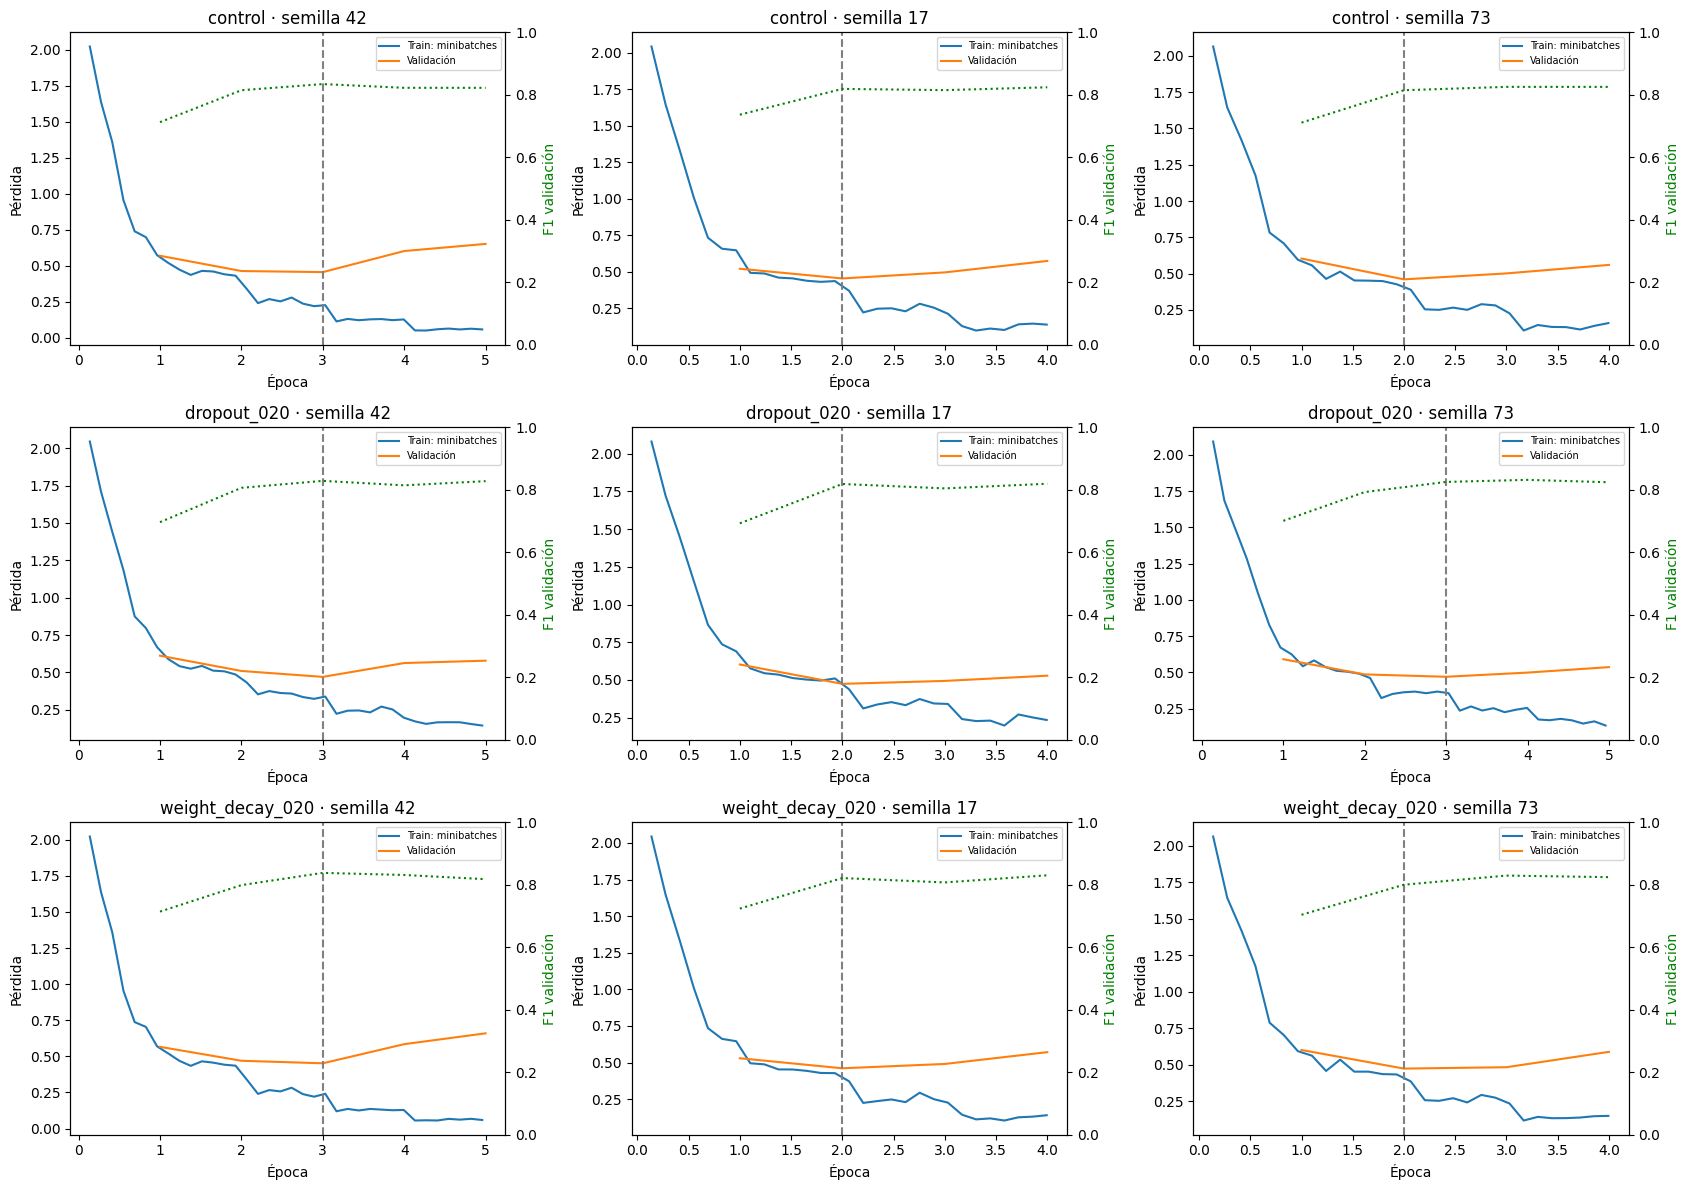

,n,mean_loss,std_loss,mean_f1,std_f1,mean_best_epoch
condition,,,,,,
control,3,0.457437,0.002441,0.823010,0.010397,2.333333
dropout_020,3,0.471377,0.002379,0.824364,0.004610,2.666667
weight_decay_020,3,0.462033,0.010559,0.820510,0.018933,2.333333


Candidata por pérdida media: control


In [7]:
analysis_rows=[]
fig,axes=plt.subplots(3,3,figsize=(17,12))
for ax,result in zip(axes.flat,results):
    work=Path(result["model_dir"]).parent
    log=json.loads((work/"training_log.json").read_text())
    valid=[x for x in log if "eval_loss" in x]
    trained=[x for x in log if "loss" in x]
    prediction=pd.read_csv(work/"evaluation/predictions.csv",dtype={"inst_key":str})
    assert prediction.inst_key.tolist()==[r["inst_key"] for r in val_rows]
    assert prediction.reference.tolist()==[r["label"] for r in val_rows]
    probs=prediction[["p_"+k for k in LABELS]].to_numpy(float)
    assert np.isfinite(probs).all() and np.allclose(probs.sum(1),1,atol=1e-5)
    y=np.array([LABEL2ID[r["label"]] for r in val_rows])
    loss=float(-np.log(np.clip(probs[np.arange(len(y)),y],np.finfo(float).tiny,1)).mean())
    minimum=min(valid,key=lambda x:x["eval_loss"])
    assert minimum["epoch"]==result["best_epoch"]
    analysis_rows.append({**result,"validation_fp32_loss":loss,
        "minimum_logged_eval_loss":minimum["eval_loss"],
        "last_logged_eval_loss":valid[-1]["eval_loss"]})
    ax.plot([x["epoch"] for x in trained],[x["loss"] for x in trained],label="Train: minibatches")
    ax.plot([x["epoch"] for x in valid],[x["eval_loss"] for x in valid],label="Validación")
    ax.axvline(result["best_epoch"],color="gray",linestyle="--")
    other=ax.twinx()
    other.plot([x["epoch"] for x in valid],[x["eval_f1_macro"] for x in valid],color="green",linestyle=":")
    other.set_ylabel("F1 validación",color="green");other.set_ylim(0,1)
    ax.set(title=result["condition"]+" · semilla "+str(result["seed"]),xlabel="Época",ylabel="Pérdida")
    ax.legend(fontsize=7)
fig.tight_layout();fig.savefig(OUTPUT_ROOT/"curvas_regularizacion.png",dpi=150);plt.show();plt.close(fig)
analysis=pd.DataFrame(analysis_rows)
analysis.to_csv(OUTPUT_ROOT/"regularization_results.csv",index=False)
summary=analysis.groupby("condition",sort=False).agg(n=("seed","count"),
    mean_loss=("validation_fp32_loss","mean"),std_loss=("validation_fp32_loss","std"),
    mean_f1=("f1_macro","mean"),std_f1=("f1_macro","std"),
    mean_best_epoch=("best_epoch","mean"))
assert summary.n.eq(3).all()
summary.to_csv(OUTPUT_ROOT/"condition_summary.csv")
save_json(OUTPUT_ROOT/"curve_data.json",analysis_rows)
display(summary)
selected_condition=min(summary.index,key=lambda k:(summary.loc[k,"mean_loss"],k!="control",k))
winners={"base":next(r for r in results if r["condition"]==selected_condition and r["seed"]==42)}
print("Candidata por pérdida media:",selected_condition)


## 8. Conservamos la candidata y los modelos de todas las pruebas

Empaquetamos la candidata de semilla 42 identificada por pérdida media. Cada
ensayo conserva además su modelo y parámetros en su carpeta. Este paquete es
exploratorio y no sustituye automáticamente el modelo utilizado en el test final.


In [8]:
import zipfile
packages = {}
for config,result in winners.items():
    model_dir = Path(result["model_dir"])
    marker = json.loads((model_dir.parent/"TRAINING_COMPLETE.json").read_text())
    verify_files(model_dir,marker["model_hashes"])
    archive = OUTPUT_ROOT/f"scibert_{config}_final.zip"
    if not archive.exists():
        packed = OUTPUT_ROOT/f".{config}_{uuid.uuid4().hex}.zip"
        with zipfile.ZipFile(packed,"w",zipfile.ZIP_DEFLATED) as z:
            for name in marker["model_hashes"]:
                z.write(model_dir/name,name)
        os.replace(packed,archive)
    with zipfile.ZipFile(archive) as z:
        names = {n for n in z.namelist() if not n.endswith("/")}
        if names != set(marker["model_hashes"]):
            raise ValueError("El paquete contiene otros archivos de modelo.")
        for name,expected in marker["model_hashes"].items():
            with z.open(name) as stream:
                digest = hashlib.sha256()
                for block in iter(lambda:stream.read(1024*1024),b""):
                    digest.update(block)
            if digest.hexdigest()!=expected:
                raise ValueError("El paquete guardado difiere del modelo seleccionado.")
    packages[config] = {"trial_id":result["trial_id"],"primary_seed":SEED,"model_dir":str(model_dir),
        "model_hashes":marker["model_hashes"],"archive":str(archive),"archive_sha256":sha256(archive),
        "learning_rate":result["learning_rate"],"weight_decay":result["weight_decay"],"best_epoch":result["best_epoch"],
        "condition":result["condition"],"dropout":result["dropout"],"checkpoint_selection":"eval_loss",
        "validation_fp32_f1_macro":result["f1_macro"]}
    tracking.client.set_tag(tracking.parent(result["trial_id"]),"selected_primary_model","true")
    tracking.client.set_tag(tracking.parent(result["trial_id"]),"model_zip_drive",str(archive))
save_json(OUTPUT_ROOT/"selected_models.json",{"study_id":RUN_ID,"models":packages,"test_scored":False})
print("Modelos seleccionados y paquetes verificados:")
display(pd.DataFrame(packages).T[["trial_id","primary_seed","validation_fp32_f1_macro","archive"]])
tracking.backup(force=True)


Modelos seleccionados y paquetes verificados:


,trial_id,primary_seed,validation_fp32_f1_macro,archive
base,regularizacion_base_control_s42,42,0.834825,/content/drive/MyDrive/MAIA_TESIS/a4/g15_scibe...


MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_base_regularizacion_01/_tracking/snapshots/20261119T005112919570Z_4e0d87ab


## 9. Conclusiones de la regularización

Entrenamos nueve modelos base con 11,616 ejemplos de entrenamiento y 1,653 de validación. Usamos máximo seis épocas y paciencia dos, seleccionando por menor pérdida. Los checkpoints elegidos quedaron entre las épocas 2 y 3; los entrenamientos terminaron entre las épocas 4 y 5.

control: pérdida FP32 media 0.4574 ± 0.0024, F1 macro 0.8230 ± 0.0104; dropout_020: pérdida FP32 media 0.4714 ± 0.0024, F1 macro 0.8244 ± 0.0046; weight_decay_020: pérdida FP32 media 0.4620 ± 0.0106, F1 macro 0.8205 ± 0.0189. El control tuvo la menor pérdida media. Dropout 0,20 aumentó el F1 medio en 0.14 puntos porcentuales, con menor dispersión, pero empeoró la pérdida. La dispersión corresponde a tres semillas, no a un intervalo de confianza.

En 9 de 9 ensayos la pérdida final de validación fue mayor que su mínimo: la parada recuperó checkpoints anteriores, pero persistieron las señales de sobreajuste. La candidata por pérdida media fue control, conservando la semilla 42; no implica superioridad en F1. La validación contiene 125 etiquetas humanas y 1.528 automáticas. No se ejecutó el test humano ni se reemplazaron las métricas finales anteriores.


In [14]:
curve_checks=[]
for item in results:
    logs=json.loads((Path(item["model_dir"]).parent/"training_log.json").read_text())
    ev=[row for row in logs if "eval_loss" in row]
    curve_checks.append(ev[-1]["eval_loss"]>min(row["eval_loss"] for row in ev))
control=summary.loc["control"]
candidate=summary.loc[selected_condition]
conclusion_text=(
    f"Entrenamos nueve modelos base con {len(train_rows):,} ejemplos de entrenamiento y "
    f"{len(val_rows):,} de validación. Usamos máximo seis épocas y paciencia dos, "
    f"seleccionando por menor pérdida. Los checkpoints elegidos quedaron entre las épocas "
    f"{min(r['best_epoch'] for r in results):g} y {max(r['best_epoch'] for r in results):g}; "
    f"los entrenamientos terminaron entre las épocas {min(r['epochs_completed'] for r in results):g} "
    f"y {max(r['epochs_completed'] for r in results):g}.\n\n"
    + "; ".join(f"{k}: pérdida FP32 media {r.mean_loss:.4f} ± {r.std_loss:.4f}, "
        f"F1 macro {r.mean_f1:.4f} ± {r.std_f1:.4f}" for k,r in summary.iterrows())
    + ". El control tuvo la menor pérdida media. Dropout 0,20 aumentó el F1 medio en "
    f"{(summary.loc['dropout_020','mean_f1']-control.mean_f1)*100:.2f} puntos porcentuales, "
    "con menor dispersión, pero empeoró la pérdida. La dispersión corresponde a tres semillas, "
    "no a un intervalo de confianza.\n\n"
    + f"En {sum(curve_checks)} de {len(curve_checks)} ensayos la pérdida final de validación "
    "fue mayor que su mínimo: la parada recuperó checkpoints anteriores, pero persistieron "
    "las señales de sobreajuste. La candidata por pérdida media fue "
    f"{selected_condition}, conservando la semilla 42; no implica superioridad en F1. "
    "La validación contiene 125 etiquetas humanas y 1.528 automáticas. "
    "No se ejecutó el test humano ni se reemplazaron las métricas finales anteriores.")
(OUTPUT_ROOT/"conclusiones.md").write_text(conclusion_text,encoding="utf-8")
names=["study_manifest.json","trial_plan.csv","trial_results.csv","regularization_results.csv",
    "condition_summary.csv","curve_data.json","curvas_regularizacion.png","selected_models.json","conclusiones.md"]
save_json(OUTPUT_ROOT/"STUDY_COMPLETE.json",{"study_id":RUN_ID,"trials":9,"test_scored":False,
    "selected_condition":selected_condition,"report_hashes":{n:sha256(OUTPUT_ROOT/n) for n in names}})
for result in results:
    parent=tracking.parent(result["trial_id"])
    for name in names+["STUDY_COMPLETE.json"]:
        tracking.client.log_artifact(parent,str(OUTPUT_ROOT/name),artifact_path="study")
tracking.backup(force=True)
release_experiment_writer(TRACKING_ROOT)
display(Markdown(conclusion_text))


MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_base_regularizacion_01/_tracking/snapshots/20261119T005515933505Z_c38a99e5


Entrenamos nueve modelos base con 11,616 ejemplos de entrenamiento y 1,653 de validación. Usamos máximo seis épocas y paciencia dos, seleccionando por menor pérdida. Los checkpoints elegidos quedaron entre las épocas 2 y 3; los entrenamientos terminaron entre las épocas 4 y 5.

control: pérdida FP32 media 0.4574 ± 0.0024, F1 macro 0.8230 ± 0.0104; dropout_020: pérdida FP32 media 0.4714 ± 0.0024, F1 macro 0.8244 ± 0.0046; weight_decay_020: pérdida FP32 media 0.4620 ± 0.0106, F1 macro 0.8205 ± 0.0189. El control tuvo la menor pérdida media. Dropout 0,20 aumentó el F1 medio en 0.14 puntos porcentuales, con menor dispersión, pero empeoró la pérdida. La dispersión corresponde a tres semillas, no a un intervalo de confianza.

En 9 de 9 ensayos la pérdida final de validación fue mayor que su mínimo: la parada recuperó checkpoints anteriores, pero persistieron las señales de sobreajuste. La candidata por pérdida media fue control, conservando la semilla 42; no implica superioridad en F1. La validación contiene 125 etiquetas humanas y 1.528 automáticas. No se ejecutó el test humano ni se reemplazaron las métricas finales anteriores.

## 10. Verificamos el cierre sin volver a entrenar

Recalculamos las métricas desde las predicciones, comprobamos las huellas de los archivos y que cada modelo corresponda al checkpoint de menor pérdida. Revisamos también la pérdida final de validación para saber si la divergencia persiste. Esta comprobación no consulta el test humano.

In [15]:
closed = json.loads((OUTPUT_ROOT/"STUDY_COMPLETE.json").read_text())
assert closed["test_scored"] is False and closed["trials"]==9
verify_files(OUTPUT_ROOT,closed["report_hashes"])
proofs=[]
for spec in PLAN:
    work=OUTPUT_ROOT/"trials"/trial_id(spec)
    verify_files(work/"model",json.loads((work/"TRAINING_COMPLETE.json").read_text())["model_hashes"])
    verify_files(work/"evaluation",json.loads((work/"EVALUATION_COMPLETE.json").read_text())["files"])
    configured=json.loads((work/"trial_spec.json").read_text())
    assert configured["trial"]==spec and configured["study"]==STUDY_SPEC
    config=json.loads((work/"model/config.json").read_text())
    assert all(config[k]==spec["dropout"] for k in ["hidden_dropout_prob","attention_probs_dropout_prob","classifier_dropout"])
    info=json.loads((work/"training_metrics.json").read_text())
    logs=json.loads((work/"training_log.json").read_text())
    ev=[x for x in logs if "eval_loss" in x]
    tr=[x for x in logs if "loss" in x]
    best=min(ev,key=lambda x:x["eval_loss"])
    assert best["epoch"]==info["best_epoch"] and info["epochs_completed"]<=6
    args=json.loads((Path(info["best_checkpoint"])/"trainer_state.json").read_text())
    assert args["best_model_checkpoint"]==info["best_checkpoint"]
    pred=pd.read_csv(work/"evaluation/predictions.csv",dtype={"inst_key":str})
    assert pred.inst_key.tolist()==[r["inst_key"] for r in val_rows]
    assert pred.reference.tolist()==[r["label"] for r in val_rows]
    probs=pred[["p_"+k for k in LABELS]].to_numpy(float)
    assert np.isfinite(probs).all() and np.allclose(probs.sum(1),1,atol=1e-5)
    assert np.array_equal(np.array(LABELS)[probs.argmax(1)],pred.predicted_label)
    f1=f1_score(pred.reference,pred.predicted_label,labels=LABELS,average="macro",zero_division=0)
    expected=next(r for r in results if r["trial_id"]==work.name)
    assert math.isclose(f1,expected["f1_macro"],abs_tol=1e-10)
    proofs.append({"trial_id":work.name,"condition":spec["condition"],"seed":spec["seed"],
        "best_epoch":info["best_epoch"],"epochs_completed":info["epochs_completed"],
        "best_eval_loss":best["eval_loss"],"last_eval_loss":ev[-1]["eval_loss"],
        "last_train_minibatch_loss":tr[-1]["loss"],"f1_macro":f1,
        "prediction_sha256":sha256(work/"evaluation/predictions.csv")})
validation_proof={"passed":True,"test_scored":False,"reviewed_trials":len(proofs),
    "reviewed_predictions":sum(len(val_rows) for _ in proofs),"split_hashes":split_hashes,
    "summary":summary.reset_index().to_dict("records"),"trials":proofs}
save_json(OUTPUT_ROOT/"validation_review.json",validation_proof)
display(pd.DataFrame(proofs).drop(columns=["prediction_sha256","trial_id"]))
print("Cierre, configuraciones, modelos y predicciones verificados.")
tracking.client.log_artifact(tracking.parent(winners["base"]["trial_id"]),
    str(OUTPUT_ROOT/"validation_review.json"),artifact_path="review")
tracking.backup(force=True)


,condition,seed,best_epoch,epochs_completed,best_eval_loss,last_eval_loss,last_train_minibatch_loss,f1_macro
0,control,42,3.0,5.0,0.457121,0.652776,0.0594,0.834825
1,control,17,2.0,4.0,0.455203,0.575063,0.1392,0.818946
2,control,73,2.0,4.0,0.460201,0.559753,0.1589,0.815259
3,dropout_020,42,3.0,5.0,0.469858,0.578323,0.1445,0.828250
4,dropout_020,17,2.0,4.0,0.474181,0.528140,0.2347,0.819271
5,dropout_020,73,3.0,5.0,0.469857,0.536309,0.1335,0.825573
6,weight_decay_020,42,3.0,5.0,0.451956,0.659476,0.0592,0.838634
7,weight_decay_020,17,2.0,4.0,0.460966,0.571027,0.1404,0.822035
8,weight_decay_020,73,2.0,4.0,0.472942,0.587797,0.1487,0.800860


Cierre, configuraciones, modelos y predicciones verificados.
MLflow respaldado: /content/drive/MyDrive/MAIA_TESIS/a4/g15_scibert_base_regularizacion_01/_tracking/snapshots/20261119T005542523102Z_14051f72
